# Extracting the Metadata Information Sorted by ID and Priming Type (meta_summary_df)

In [25]:
import os
import pandas as pd

# Define the folder path containing the CSV files
folder_path = r"data"

# Function to extract metadata from each VR summary file
def extract_vr_summary_data(file_path):
    """Extracts relevant fields from a VR summary CSV."""
    
    # Read the entire CSV file without headers, treating each row as a single entry
    data = pd.read_csv(file_path, header=None)
    
    # Initialize a dictionary to store the extracted metadata
    summary = {}

    # Loop through each row in the DataFrame to find and extract specific metadata fields
    for _, row in data.iterrows():
        row_str = row[0]  # Treat each row as a string for easier keyword searching
        # Check if the row contains specific metadata keywords and extract the value after '='
        if "ID" in row_str:
            summary["ID"] = row_str.split('=')[-1].strip()
        elif "Depth Sections" in row_str:
            summary["Depth Sections"] = row_str.split('=')[-1].strip()
        elif "Angle Sections" in row_str:
            summary["Angle Sections"] = row_str.split('=')[-1].strip()
        elif "Angle deviation" in row_str:
            summary["Angle Deviation"] = row_str.split('=')[-1].strip()
        elif "Guide gap" in row_str:
            summary["Guide Gap"] = row_str.split('=')[-1].strip()
        elif "Priming type" in row_str:
            summary["Priming Type"] = row_str.split('=')[-1].strip()
        elif "Data Count" in row_str:
            summary["Data Count"] = row_str.split('=')[-1].strip()
        elif "Desired Target" in row_str:
            summary["Desired Target"] = row_str.split('=')[-1].strip()

    return summary

# Initialize a list to store metadata for each file
metadata_list = []

# Loop through each CSV file in the folder
for file_name in os.listdir(folder_path):
    if file_name.endswith('.csv'):
        file_path = os.path.join(folder_path, file_name)
        # Extract metadata for each file and add it to the list
        metadata = extract_vr_summary_data(file_path)
        metadata_list.append(metadata)

# Create a DataFrame from the list of metadata dictionaries
metadata_df = pd.DataFrame(metadata_list)

# Display the DataFrame without extra data
print("\nExtracted Metadata Summary:")
#meta_summary_df = metadata_df[['ID', 'Depth Sections', 'Angle Sections','Angle Deviation', 'Priming Type', 'Data Count', 'Desired Target']].sort_values(by=['ID','Priming Type'], na_position='last').reset_index(drop=True)
meta_summary_df = metadata_df[['ID', 'Priming Type']].sort_values(by=['ID','Priming Type'], na_position='last').reset_index(drop=True)
print(meta_summary_df)  # This will only print the summary DataFrame

# Step 3: Save the extracted data to a new CSV file for easy reference and sharing
output_csv = r"Documents"
meta_summary_df.to_csv(output_csv, index=False)  # Saves the DataFrame to a CSV file without row indices

#print(f"\nExtraction completed and saved to {output_csv}")



Extracted Metadata Summary:
         ID Priming Type
0   ID : 11       Avatar
1   ID : 11         None
2   ID : 11       Object
3   ID : 12       Avatar
4   ID : 12         None
5   ID : 12       Object
6   ID : 13       Avatar
7   ID : 13         None
8   ID : 13       Object
9   ID : 14       Avatar
10  ID : 14         None
11  ID : 14       Object
12  ID : 15       Avatar
13  ID : 15         None
14  ID : 15       Object
15  ID : 16       Avatar
16  ID : 16         None
17  ID : 16       Object
18  ID : 17       Avatar
19  ID : 17         None
20  ID : 17       Object
21  ID : 18       Avatar
22  ID : 18         None
23  ID : 18       Object
24  ID : 19       Avatar
25  ID : 19         None
26  ID : 19       Object
27  ID : 20       Avatar
28  ID : 20         None
29  ID : 20       Object


# Filter data with new columns of Target Positions, Hand Pressed Positions and Distance Errors (filter_data_df)

In [26]:

from IPython.display import display


# Initialize a list to store processed data from each CSV file
data_list = []

# Loop through each CSV file in the folder
for file_name in os.listdir(folder_path):
    if file_name.endswith('.csv'):
        # Define the full path of the CSV file
        file_path = os.path.join(folder_path, file_name)
        
        # Step 1: Read the CSV file from the 9th row onwards by skipping the first 8 rows
        final_data = pd.read_csv(file_path, skiprows=8, header=None)

        # Step 2: Remove any extra spaces between words in the first column
        final_data[0] = final_data[0].str.strip().replace(r'\s+', ' ', regex=True)

        # Step 3: Split the cleaned column into separate columns
        df_split = final_data[0].str.split(" ", expand=True)

        # Step 4: Set the first row as the header
        df_split.columns = df_split.iloc[0]
        df_split = df_split[1:]  # Remove the header row and keep the data
        
        # Step 5: Remove duplicates based on the 'PressedHandCounter' column
        df_unique = df_split.drop_duplicates(subset='PressedHandCounter', keep='first')

        # Step 6: Drop the second row (index 1)
        df_unique = df_unique.drop(1)

        # Append the cleaned and processed DataFrame to the list
        data_list.append(df_unique)

# Step 7: Concatenate all processed data into a single DataFrame
filter_data_df = pd.concat(data_list, ignore_index=True)

# Step 8: Ensure the columns that need numeric values are converted to numeric
numeric_columns = ['TargetPosX', 'TargetPosY', 'TargetPosZ', 'HandPressedX', 'HandPressedY', 'HandPressedZ']
for col in numeric_columns:
    filter_data_df[col] = pd.to_numeric(filter_data_df[col], errors='coerce')

# Step 9: Add new columns for 'Target Position' and 'Pressed Hand Position'
filter_data_df['Target Position'] = filter_data_df[['TargetPosX', 'TargetPosY', 'TargetPosZ']].sum(axis=1)
filter_data_df['Pressed Hand Position'] = filter_data_df[['HandPressedX', 'HandPressedY', 'HandPressedZ']].sum(axis=1)

# Step 10: Calculate the 'Distance Error' and add it as a new column
filter_data_df['Distance Error'] = np.sqrt(
    (filter_data_df['TargetPosX'] - filter_data_df['HandPressedX'])**2 +
    (filter_data_df['TargetPosY'] - filter_data_df['HandPressedY'])**2 +
    (filter_data_df['TargetPosZ'] - filter_data_df['HandPressedZ'])**2
)

# Step 11: Select specific columns to include in the final output
# List the columns you want to keep
selected_columns = [
    'Trial', 
    'ShuffleOrder', 
     'DepthSection',
    'AngleSection',
    'TargetPosX', 
    'TargetPosY', 
    'TargetPosZ', 
    'HandPressedX', 
    'HandPressedY', 
    'HandPressedZ', 
    'Target Position', 
    'Pressed Hand Position', 
    'Distance Error'
]

# Filter the DataFrame to include only the selected columns
if all(col in filter_data_df.columns for col in selected_columns):
    final_df = filter_data_df[selected_columns]
else:
    missing_columns = [col for col in selected_columns if col not in filter_data_df.columns]
    raise ValueError(f"The following required columns are missing: {missing_columns}")

# Step 12: Save the final DataFrame to a new CSV file
#output_path = os.path.join(folder_path, "selected_columns_output.csv")
#final_df.to_csv(output_path, index=False)

# Step 13: Display the final DataFrame
display(final_df)

# Print confirmation
#Sprint(f"Processed data with selected columns saved to {output_path}")


,Trial,ShuffleOrder,DepthSection,AngleSection,TargetPosX,TargetPosY,TargetPosZ,HandPressedX,HandPressedY,HandPressedZ,Target Position,Pressed Hand Position,Distance Error
0,0,50,2,1,0.498663,1.662207,-0.142908,0.502462,1.652053,-0.168776,2.017961,1.985739,0.028048
1,1,53,2,1,0.458143,1.662207,-0.080185,0.450023,1.659096,-0.085403,2.040165,2.023716,0.010141
2,2,57,2,1,0.498453,1.662207,0.257171,0.492565,1.663585,0.251695,2.417832,2.407845,0.008158
3,3,7,2,1,0.560390,1.662207,0.346876,0.550087,1.665014,0.346825,2.569473,2.561926,0.010679
4,4,20,2,1,0.651864,1.662207,-0.080067,0.649768,1.657363,-0.099030,2.234004,2.208101,0.019684
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1795,55,7,2,3,-0.268781,1.744840,-0.060961,-0.311761,1.746487,-0.085600,1.415098,1.349126,0.049569
1796,56,36,2,3,0.090982,1.744840,0.145064,0.103068,1.738430,0.154062,1.980885,1.995561,0.016375
1797,57,20,2,3,-0.224826,1.744840,0.049072,-0.272582,1.748284,0.031253,1.569086,1.506956,0.051088
1798,58,26,2,3,-0.108334,1.744840,0.213522,-0.145851,1.745251,0.216325,1.850028,1.815725,0.037624


# Final Table with ID Priming type and target, hand and error

In [58]:


# Function to extract metadata from each VR summary file
def extract_vr_summary_data(file_path):
    """Extracts relevant fields from a VR summary CSV."""
    data = pd.read_csv(file_path, header=None)
    summary = {}

    for _, row in data.iterrows():
        row_str = row[0]
        if "ID" in row_str:
            summary["ID"] = row_str.split('=')[-1].strip()
        elif "Priming type" in row_str:
            summary["Priming Type"] = row_str.split('=')[-1].strip()

    return summary

# Initialize lists for metadata and real data
metadata_list = []
data_list = []

# Process each CSV file in the folder
for file_name in os.listdir(folder_path):
    if file_name.endswith('.csv'):
        file_path = os.path.join(folder_path, file_name)

        # Extract metadata
        metadata = extract_vr_summary_data(file_path)
        metadata_list.append(metadata)

        # Extract real data (starting from the 9th row)
        final_data = pd.read_csv(file_path, skiprows=8, header=None)
        final_data[0] = final_data[0].str.strip().replace(r'\s+', ' ', regex=True)
        df_split = final_data[0].str.split(" ", expand=True)
        df_split.columns = df_split.iloc[0]
        df_split = df_split[1:]  # Remove the header row
        df_unique = df_split.drop_duplicates(subset='PressedHandCounter', keep='first').drop(1)

        # Ensure numeric columns are converted
        for col in ['TargetPosX', 'TargetPosY', 'TargetPosZ', 'HandPressedX', 'HandPressedY', 'HandPressedZ']:
            df_unique[col] = pd.to_numeric(df_unique[col], errors='coerce')

        # Add calculated columns
        df_unique['Target Position'] = df_unique[['TargetPosX', 'TargetPosY', 'TargetPosZ']].sum(axis=1)
        df_unique['Pressed Hand Position'] = df_unique[['HandPressedX', 'HandPressedY', 'HandPressedZ']].sum(axis=1)
        df_unique['Distance Error'] = np.sqrt(
            (df_unique['TargetPosX'] - df_unique['HandPressedX'])**2 +
            (df_unique['TargetPosY'] - df_unique['HandPressedY'])**2 +
            (df_unique['TargetPosZ'] - df_unique['HandPressedZ'])**2
        )

        # Add metadata columns to real data
        df_unique['ID'] = metadata.get("ID", None)
        df_unique['Priming Type'] = metadata.get("Priming Type", None)

        # Append processed real data
        data_list.append(df_unique)

# Combine all metadata into a DataFrame
metadata_df = pd.DataFrame(metadata_list)
meta_summary_df = metadata_df[['ID', 'Priming Type']].sort_values(by=['ID', 'Priming Type'], na_position='last').reset_index(drop=True)

# Combine all real data into a single DataFrame
filter_data_df = pd.concat(data_list, ignore_index=True)

# Filter and keep only the required columns
final_data = filter_data_df[['ID', 'Priming Type', 'DepthSection', 'AngleSection', 'TargetPosX','TargetPosZ', 'HandPressedX', 'HandPressedZ',
                             'Target Position', 'Pressed Hand Position', 'Distance Error']]


# Define the new folder path
new_folder_path = r"ProprioceptionVR_Data22dec"

# Ensure the new folder exists; if not, create it
os.makedirs(new_folder_path, exist_ok=True)

# Define the output path in the new folder
output_path = os.path.join(new_folder_path, "filtered_combined_data.csv")

# Save the filtered data to the new folder
final_df.to_csv(output_path, index=False)

# Print confirmation of where the file is saved
print(f"Processed data saved to: {output_path}")


# Save the filtered data to a new CSV file
#output_path = os.path.join(folder_path, "filtered_combined_data.csv")
#final_data.to_csv(output_path, index=False)

# Display the filtered DataFrame
#print("\nFiltered Combined Data:")
display(final_data)

# Confirmation message
#print(f"\nFiltered combined data saved to {output_path}")


Processed data saved to: ProprioceptionVR_Data22dec\filtered_combined_data.csv


,ID,Priming Type,DepthSection,AngleSection,TargetPosX,TargetPosZ,HandPressedX,HandPressedZ,Target Position,Pressed Hand Position,Distance Error
0,ID : 11,None,2,1,0.498663,-0.142908,0.502462,-0.168776,2.017961,1.985739,0.028048
1,ID : 11,None,2,1,0.458143,-0.080185,0.450023,-0.085403,2.040165,2.023716,0.010141
2,ID : 11,None,2,1,0.498453,0.257171,0.492565,0.251695,2.417832,2.407845,0.008158
3,ID : 11,None,2,1,0.560390,0.346876,0.550087,0.346825,2.569473,2.561926,0.010679
4,ID : 11,None,2,1,0.651864,-0.080067,0.649768,-0.099030,2.234004,2.208101,0.019684
...,...,...,...,...,...,...,...,...,...,...,...
1795,ID : 20,Avatar,2,3,-0.268781,-0.060961,-0.311761,-0.085600,1.415098,1.349126,0.049569
1796,ID : 20,Avatar,2,3,0.090982,0.145064,0.103068,0.154062,1.980885,1.995561,0.016375
1797,ID : 20,Avatar,2,3,-0.224826,0.049072,-0.272582,0.031253,1.569086,1.506956,0.051088
1798,ID : 20,Avatar,2,3,-0.108334,0.213522,-0.145851,0.216325,1.850028,1.815725,0.037624


In [59]:

# Extract digits using a regular expression
final_data['ID'] = final_data['ID'].str.extract(r'(\d+)', expand=False)

# Convert ID to an integer type (optional)
final_data['ID'] = final_data['ID'].astype(int)

# Display the modified DataFrame
final_data.head()


C:\Users\User\AppData\Local\Temp\ipykernel_84204\4104554827.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_data['ID'] = final_data['ID'].str.extract(r'(\d+)', expand=False)
C:\Users\User\AppData\Local\Temp\ipykernel_84204\4104554827.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_data['ID'] = final_data['ID'].astype(int)


,ID,Priming Type,DepthSection,AngleSection,TargetPosX,TargetPosZ,HandPressedX,HandPressedZ,Target Position,Pressed Hand Position,Distance Error
0,11,None,2,1,0.498663,-0.142908,0.502462,-0.168776,2.017961,1.985739,0.028048
1,11,None,2,1,0.458143,-0.080185,0.450023,-0.085403,2.040165,2.023716,0.010141
2,11,None,2,1,0.498453,0.257171,0.492565,0.251695,2.417832,2.407845,0.008158
3,11,None,2,1,0.560390,0.346876,0.550087,0.346825,2.569473,2.561926,0.010679
4,11,None,2,1,0.651864,-0.080067,0.649768,-0.099030,2.234004,2.208101,0.019684


# DepthSection and AngleSection Mean

  DepthSection  Distance Error
0            0        0.029621
1            1        0.025355
2            2        0.028747


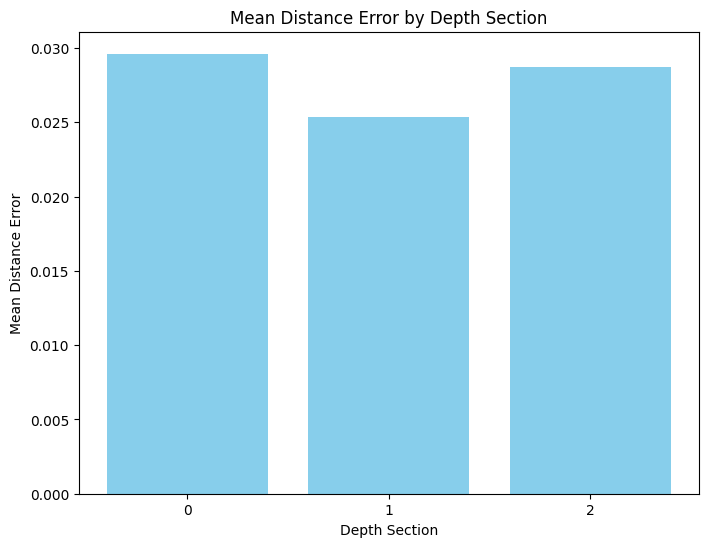

  AngleSection  Distance Error
0            0        0.026958
1            1        0.027409
2            2        0.029503
3            3        0.027762


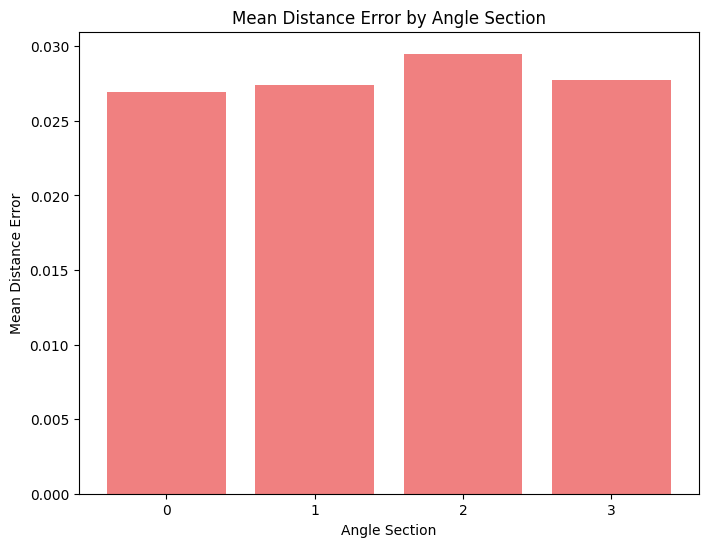

In [44]:

import matplotlib.pyplot as plt

# Assuming `df` is your DataFrame containing the necessary columns

# Calculate mean of 'Distance Error' by DepthSection
mean_diff_depth = final_data.groupby('DepthSection')['Distance Error'].mean().reset_index()

# Display the result
print(mean_diff_depth)

# Plotting a bar chart for DepthSection
plt.figure(figsize=(8, 6))
plt.bar(mean_diff_depth['DepthSection'], mean_diff_depth['Distance Error'], color='skyblue')
plt.xlabel('Depth Section')
plt.ylabel('Mean Distance Error')
plt.title('Mean Distance Error by Depth Section')
plt.xticks(mean_diff_depth['DepthSection'])
plt.show()

# Calculate mean of 'Distance Error' by AngleSection
mean_diff_angle = final_data.groupby('AngleSection')['Distance Error'].mean().reset_index()

# Display the result
print(mean_diff_angle)

# Plotting a bar chart for AngleSection
plt.figure(figsize=(8, 6))
plt.bar(mean_diff_angle['AngleSection'], mean_diff_angle['Distance Error'], color='lightcoral')
plt.xlabel('Angle Section')
plt.ylabel('Mean Distance Error')
plt.title('Mean Distance Error by Angle Section')
plt.xticks(mean_diff_angle['AngleSection'])
plt.show()


# Grid Plots


In [60]:
final_data.head()

,ID,Priming Type,DepthSection,AngleSection,TargetPosX,TargetPosZ,HandPressedX,HandPressedZ,Target Position,Pressed Hand Position,Distance Error
0,11,None,2,1,0.498663,-0.142908,0.502462,-0.168776,2.017961,1.985739,0.028048
1,11,None,2,1,0.458143,-0.080185,0.450023,-0.085403,2.040165,2.023716,0.010141
2,11,None,2,1,0.498453,0.257171,0.492565,0.251695,2.417832,2.407845,0.008158
3,11,None,2,1,0.560390,0.346876,0.550087,0.346825,2.569473,2.561926,0.010679
4,11,None,2,1,0.651864,-0.080067,0.649768,-0.099030,2.234004,2.208101,0.019684


C:\Users\User\AppData\Local\Temp\ipykernel_84204\2148384343.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_data['Section'] = final_data['DepthSection'].astype(str) + '-' + final_data['AngleSection'].astype(str)


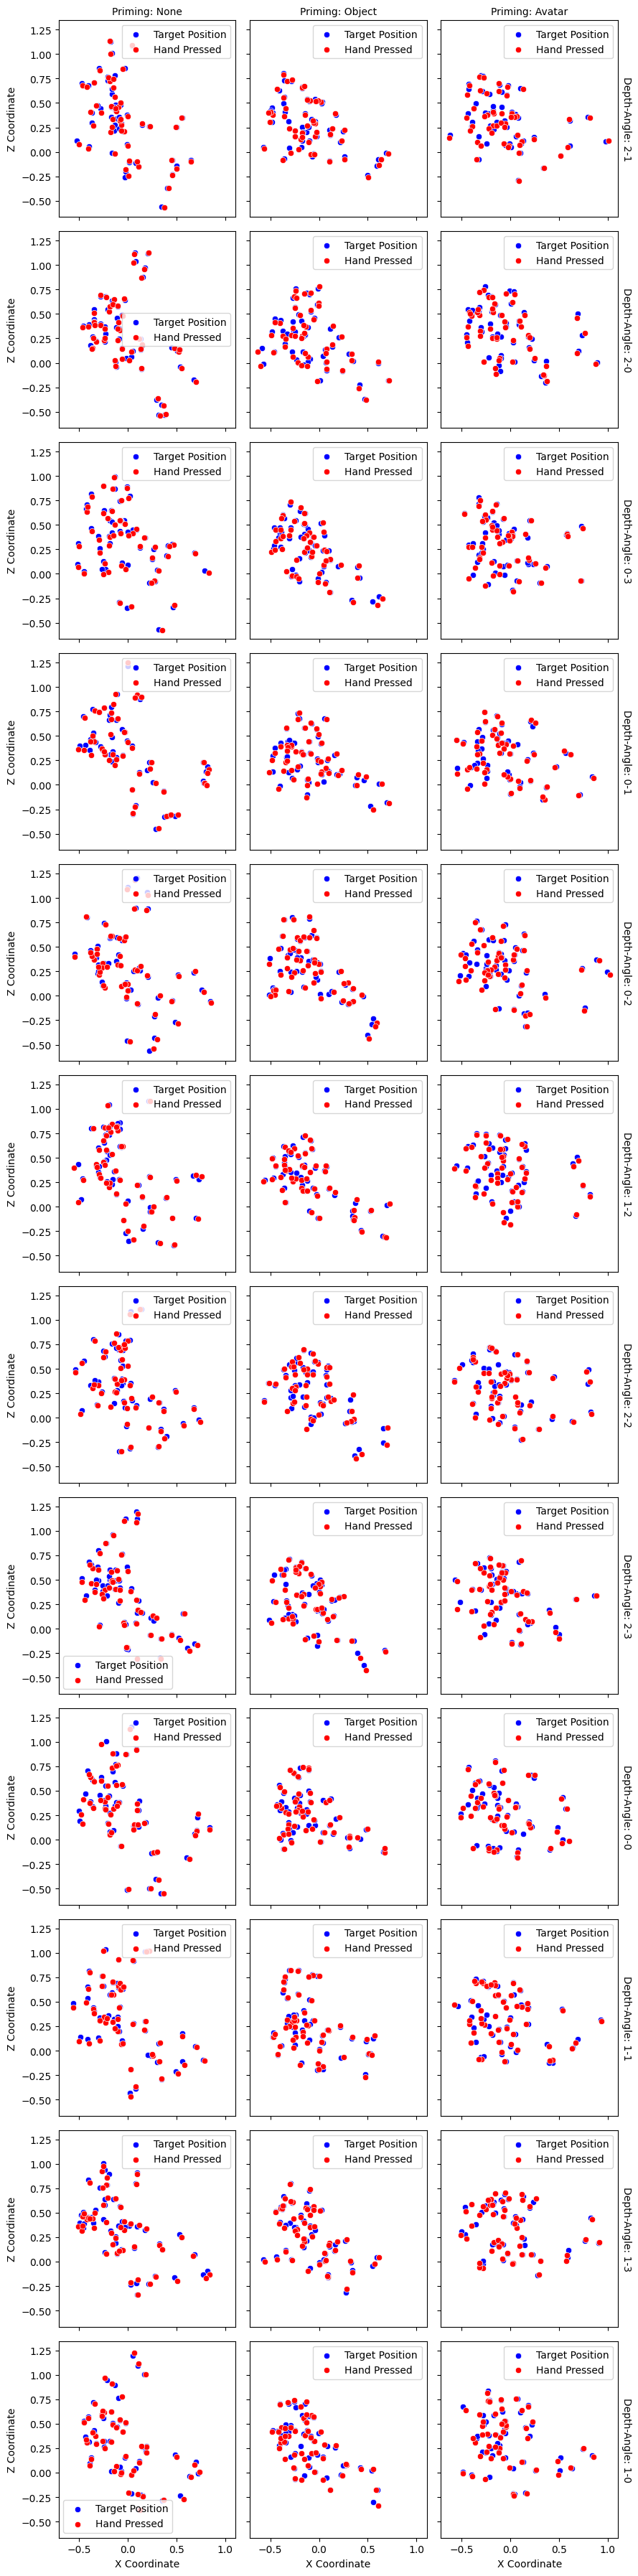

In [68]:


# Create a new column for combined DepthSection and AngleSection
final_data['Section'] = final_data['DepthSection'].astype(str) + '-' + final_data['AngleSection'].astype(str)

# FacetGrid for plotting
g = sns.FacetGrid(final_data, col='Priming Type', row='Section', margin_titles=True, despine=False)
g.map_dataframe(sns.scatterplot, x='TargetPosX', y='TargetPosZ', color='blue', label='Target Position')
g.map_dataframe(sns.scatterplot, x='HandPressedX', y='HandPressedZ', color='red', label='Hand Pressed')

# Add legend
for ax in g.axes.flat:
    ax.legend(loc='best')

# Set titles and labels
g.set_axis_labels("X Coordinate", "Z Coordinate")
g.set_titles(row_template="Depth-Angle: {row_name}", col_template="Priming: {col_name}")
g.tight_layout()

plt.show()


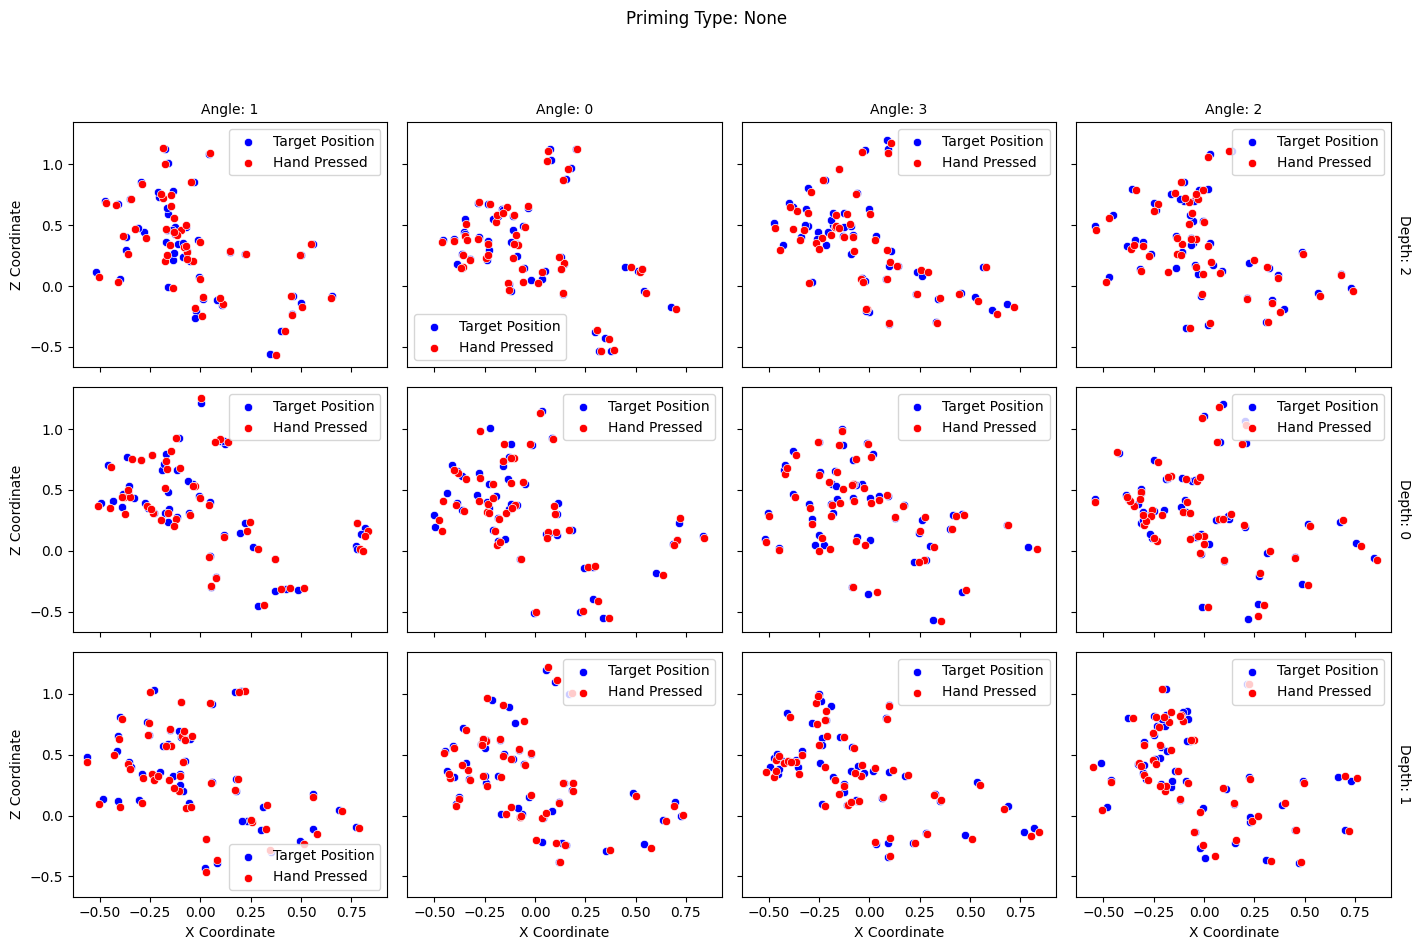

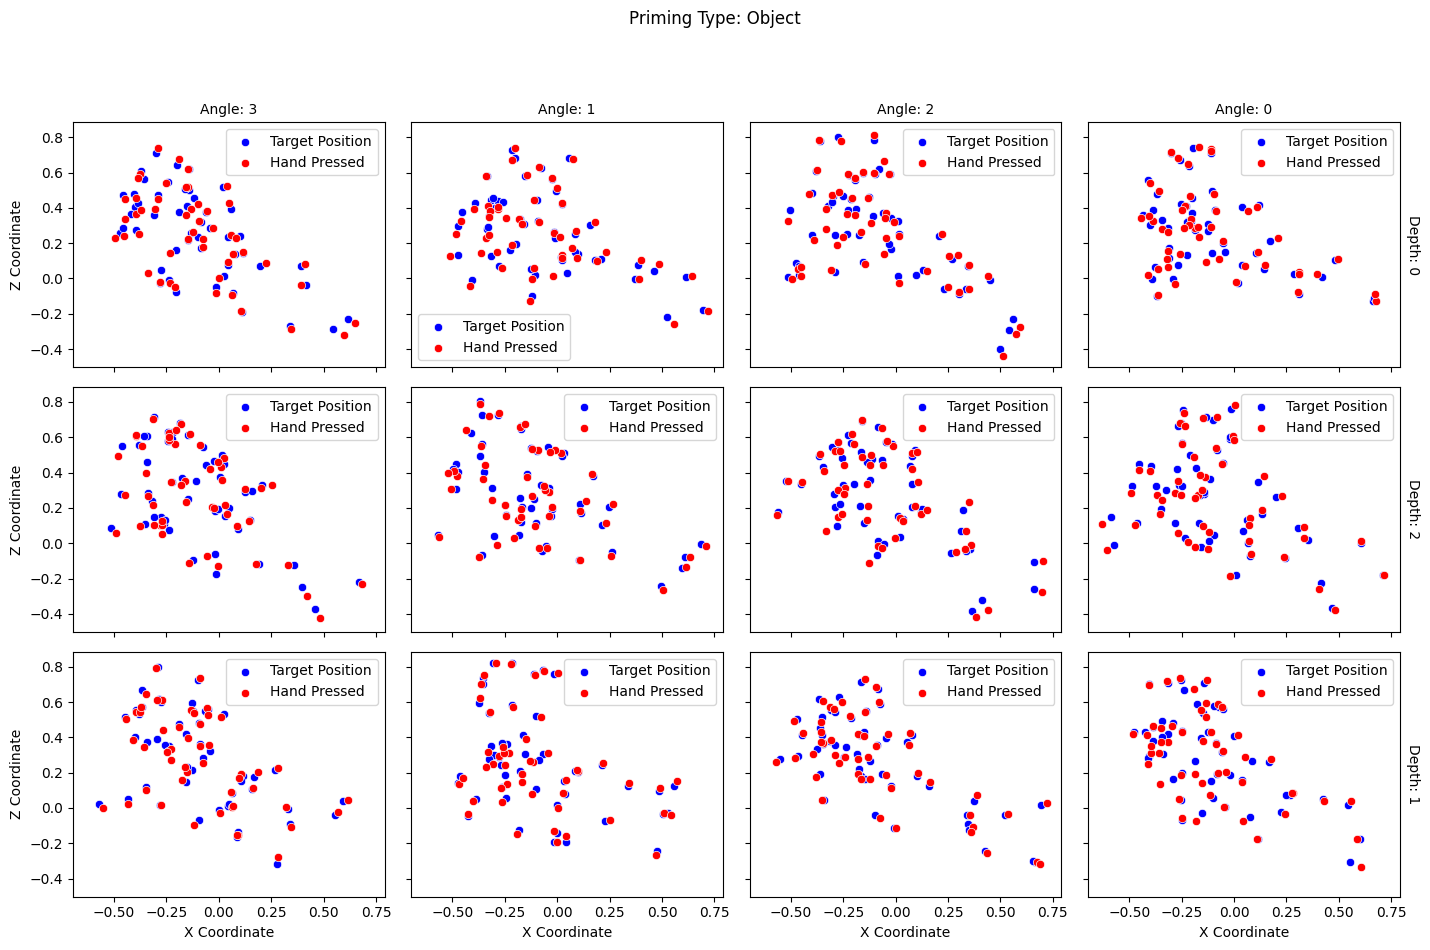

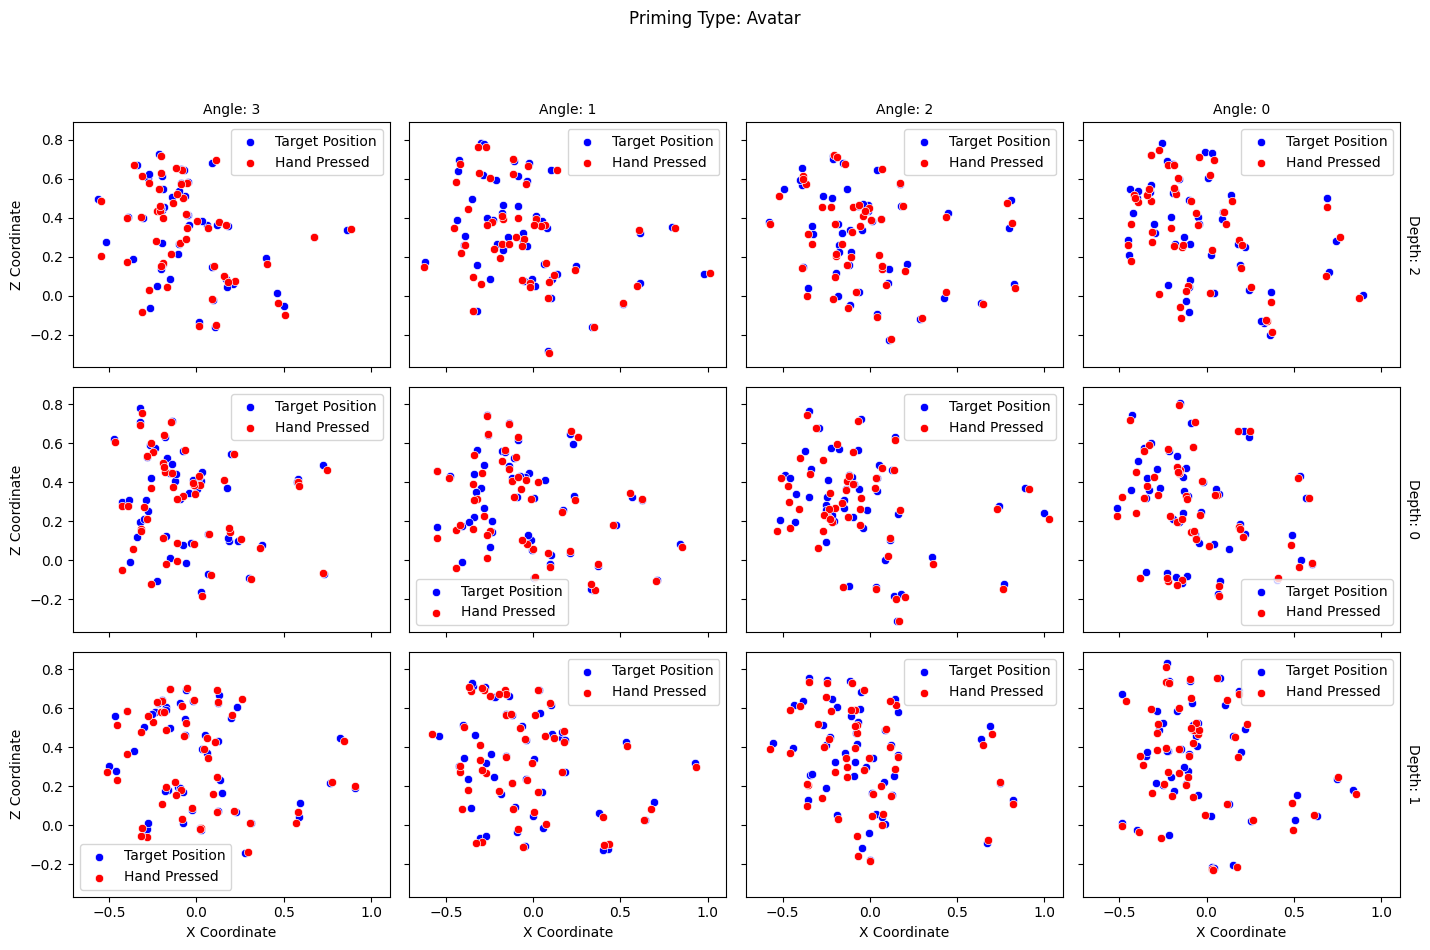

In [69]:

# Create scatter grid plots for each Priming Type
priming_types = final_data['Priming Type'].unique()

for priming in priming_types:
    priming_df = final_data[final_data['Priming Type'] == priming]  # Filter data for the current priming type

    # Create scatter grid with DepthSection and AngleSection
    g = sns.FacetGrid(
        priming_df, 
        row="DepthSection", 
        col="AngleSection", 
        margin_titles=True, 
        despine=False, 
        height=3, 
        aspect=1.2
    )

    # Scatter plots for Target and Hand Pressed positions
    g.map_dataframe(
        sns.scatterplot, 
        x="TargetPosX", 
        y="TargetPosZ", 
        color="blue", 
        label="Target Position"
    )
    g.map_dataframe(
        sns.scatterplot, 
        x="HandPressedX", 
        y="HandPressedZ", 
        color="red", 
        label="Hand Pressed"
    )

    # Add legend to each subplot
    for ax in g.axes.flat:
        ax.legend(loc="best")

    # Set common labels and titles
    g.set_axis_labels("X Coordinate", "Z Coordinate")
    g.set_titles(row_template="Depth: {row_name}", col_template="Angle: {col_name}")
    g.fig.suptitle(f"Priming Type: {priming}", y=1.05)  # Add a super title for each grid
    g.tight_layout()

    # Show the plot for the current Priming Type
    plt.show()


Sample Data:


,DepthSection,AngleSection,Target Position,Pressed Hand Position
0,2,1,2.017961,1.985739
1,2,1,2.040165,2.023716
2,2,1,2.417832,2.407845
3,2,1,2.569473,2.561926
4,2,1,2.234004,2.208101


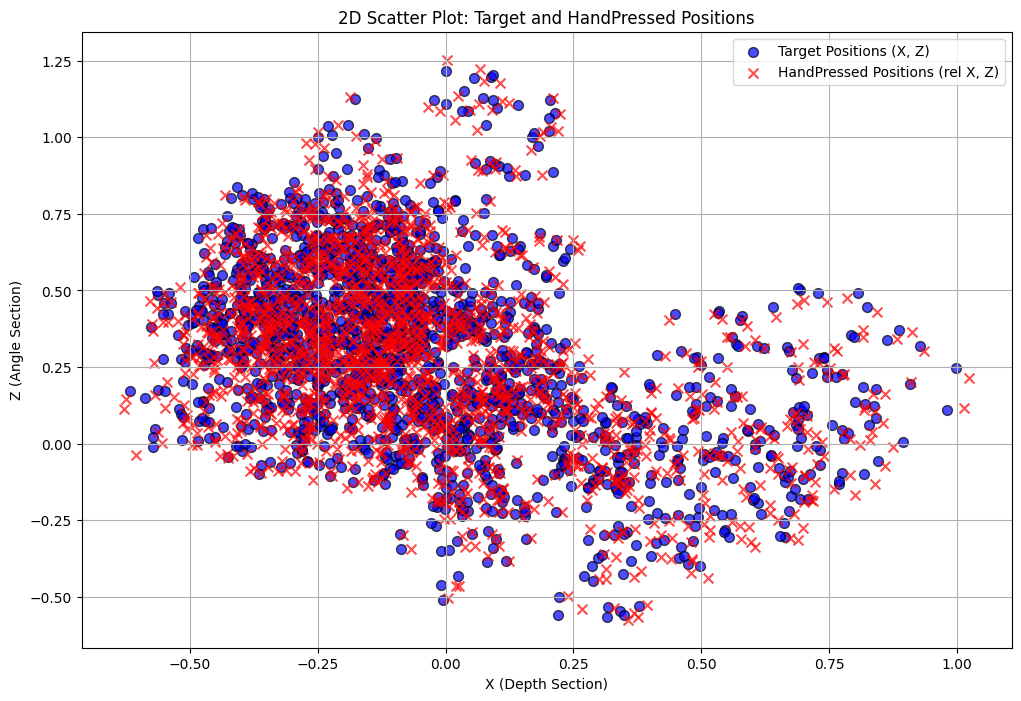

In [30]:

# Verify the data
print("Sample Data:")
display(final_data[['DepthSection', 'AngleSection', 'Target Position', 'Pressed Hand Position']].head())

# Plot Target and Pressed Hand Positions separately for clarity
plt.figure(figsize=(12, 8))

# Scatter plot for Target Positions (using X, Y, Z components)
plt.scatter(
    filter_data_df['TargetPosX'], 
    filter_data_df['TargetPosZ'], 
    c='blue', 
    s=50, 
    label='Target Positions (X, Z)', 
    alpha=0.7, 
    edgecolor='k'
)

# Scatter plot for Pressed Hand Positions (using X, Y, Z components)
plt.scatter(
    filter_data_df['HandPressedX'], 
    filter_data_df['HandPressedZ'], 
    c='red', 
    s=50, 
    marker='x', 
    label='HandPressed Positions (rel X, Z)', 
    alpha=0.7
)

# Add labels and title
plt.xlabel('X (Depth Section)')
plt.ylabel('Z (Angle Section)')
plt.title('2D Scatter Plot: Target and HandPressed Positions')
plt.legend()
plt.grid(True)
plt.show()


# Translate the Target Generted postion to (0,0), and Hand Pressed (Relative Positions)

In [48]:

# Function to extract metadata from each VR summary file
def extract_vr_summary_data(file_path):
    """Extracts relevant fields from a VR summary CSV."""
    data = pd.read_csv(file_path, header=None)
    summary = {}

    for _, row in data.iterrows():
        row_str = str(row[0])
        if "ID" in row_str:
            summary["ID"] = row_str.split('=')[-1].strip()
        elif "Priming type" in row_str:
            summary["Priming Type"] = row_str.split('=')[-1].strip()

    return summary

# Initialize lists for metadata and real data
metadata_list = []
data_list = []

# Process each CSV file in the folder
for file_name in os.listdir(folder_path):
    if file_name.endswith('.csv'):
        file_path = os.path.join(folder_path, file_name)

        # Extract metadata
        metadata = extract_vr_summary_data(file_path)
        metadata_list.append(metadata)

        # Extract real data (starting from the 9th row)
        final_data = pd.read_csv(file_path, skiprows=8, header=None)
        
        # Ensure the first column contains strings before applying string operations
        final_data[0] = final_data[0].astype(str).str.strip().replace(r'\s+', ' ', regex=True)

        # Split the column into multiple columns based on spaces
        df_split = final_data[0].str.split(" ", expand=True)
        df_split.columns = df_split.iloc[0]  # Set column names from the first row
        df_split = df_split[1:]  # Remove the header row

        # Check if required columns exist
        required_columns = ['TargetPosX', 'TargetPosZ', 'HandPressedX', 'HandPressedZ', 
                            'DepthSection', 'AngleSection']
        missing_columns = [col for col in required_columns if col not in df_split.columns]

        if missing_columns:
            print(f"Warning: Missing columns {missing_columns} in file {file_name}. Skipping...")
            continue

        # Drop duplicates based on 'PressedHandCounter' if available
        if 'PressedHandCounter' in df_split.columns:
            df_unique = df_split.drop_duplicates(subset='PressedHandCounter', keep='first')
        else:
            df_unique = df_split.copy()

        # Ensure numeric columns are converted
        for col in ['TargetPosX', 'TargetPosZ', 'HandPressedX', 'HandPressedZ']:
            df_unique[col] = pd.to_numeric(df_unique[col], errors='coerce')

        # Translate TargetPosX and TargetPosZ to (0, 0)
        df_unique['TargetPosX_Trans'] = 0
        df_unique['TargetPosZ_Trans'] = 0

        # Adjust HandPressedX and HandPressedZ relative to TargetPosX and TargetPosZ
        df_unique['HandPressedX_Rel'] = df_unique['HandPressedX'] - df_unique['TargetPosX']
        df_unique['HandPressedZ_Rel'] = df_unique['HandPressedZ'] - df_unique['TargetPosZ']

        # Create a new DataFrame with required columns
        translate_newdf = df_unique[[
            'DepthSection', 'AngleSection', 
            'TargetPosX_Trans', 'TargetPosZ_Trans', 
            'HandPressedX_Rel', 'HandPressedZ_Rel'
        ]].copy()

        # Add metadata columns
        translate_newdf['ID'] = metadata.get("ID", None)
        translate_newdf['Priming Type'] = metadata.get("Priming Type", None)

        # Reorder columns for clarity
        translate_newdf = translate_newdf[[
            'ID', 'Priming Type', 'DepthSection', 'AngleSection', 
            'TargetPosX_Trans', 'TargetPosZ_Trans', 'HandPressedX_Rel', 'HandPressedZ_Rel'
        ]]

        # Append processed data
        data_list.append(translate_newdf)

# Combine all translated data into a single DataFrame
final_translate_newdf = pd.concat(data_list, ignore_index=True)

# Display results directly in the editor
print("\nProcessed Translated Data (New DataFrame):")
display(final_translate_newdf)


# Define the new folder path
new_folder_path = r"output"

# Ensure the new folder exists; if not, create it
os.makedirs(new_folder_path, exist_ok=True)

# Define the output path in the new folder
output_path = os.path.join(new_folder_path, "filtered_combined_data.csv")

# Save the filtered data to the new folder
final_df.to_csv(output_path, index=False)

# Print confirmation of where the file is saved
print(f"Processed data saved to: {output_path}")



C:\Users\User\AppData\Local\Temp\ipykernel_84204\3404139861.py:57: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_unique[col] = pd.to_numeric(df_unique[col], errors='coerce')
C:\Users\User\AppData\Local\Temp\ipykernel_84204\3404139861.py:60: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_unique['TargetPosX_Trans'] = 0
C:\Users\User\AppData\Local\Temp\ipykernel_84204\3404139861.py:61: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,co


Processed Translated Data (New DataFrame):


C:\Users\User\AppData\Local\Temp\ipykernel_84204\3404139861.py:57: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_unique[col] = pd.to_numeric(df_unique[col], errors='coerce')
C:\Users\User\AppData\Local\Temp\ipykernel_84204\3404139861.py:60: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_unique['TargetPosX_Trans'] = 0
C:\Users\User\AppData\Local\Temp\ipykernel_84204\3404139861.py:61: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,co

,ID,Priming Type,DepthSection,AngleSection,TargetPosX_Trans,TargetPosZ_Trans,HandPressedX_Rel,HandPressedZ_Rel
0,ID : 11,None,2,1,0,0,-0.498663,0.142908
1,ID : 11,None,2,1,0,0,0.003800,-0.025868
2,ID : 11,None,2,1,0,0,-0.008120,-0.005218
3,ID : 11,None,2,1,0,0,-0.005888,-0.005476
4,ID : 11,None,2,1,0,0,-0.010304,-0.000050
...,...,...,...,...,...,...,...,...
1825,ID : 20,Avatar,2,3,0,0,-0.042980,-0.024638
1826,ID : 20,Avatar,2,3,0,0,0.012087,0.008999
1827,ID : 20,Avatar,2,3,0,0,-0.047756,-0.017818
1828,ID : 20,Avatar,2,3,0,0,-0.037517,0.002803


Processed data saved to: output\filtered_combined_data.csv


In [49]:
final_translate_newdf.head()

,ID,Priming Type,DepthSection,AngleSection,TargetPosX_Trans,TargetPosZ_Trans,HandPressedX_Rel,HandPressedZ_Rel
0,ID : 11,None,2,1,0,0,-0.498663,0.142908
1,ID : 11,None,2,1,0,0,0.003800,-0.025868
2,ID : 11,None,2,1,0,0,-0.008120,-0.005218
3,ID : 11,None,2,1,0,0,-0.005888,-0.005476
4,ID : 11,None,2,1,0,0,-0.010304,-0.000050


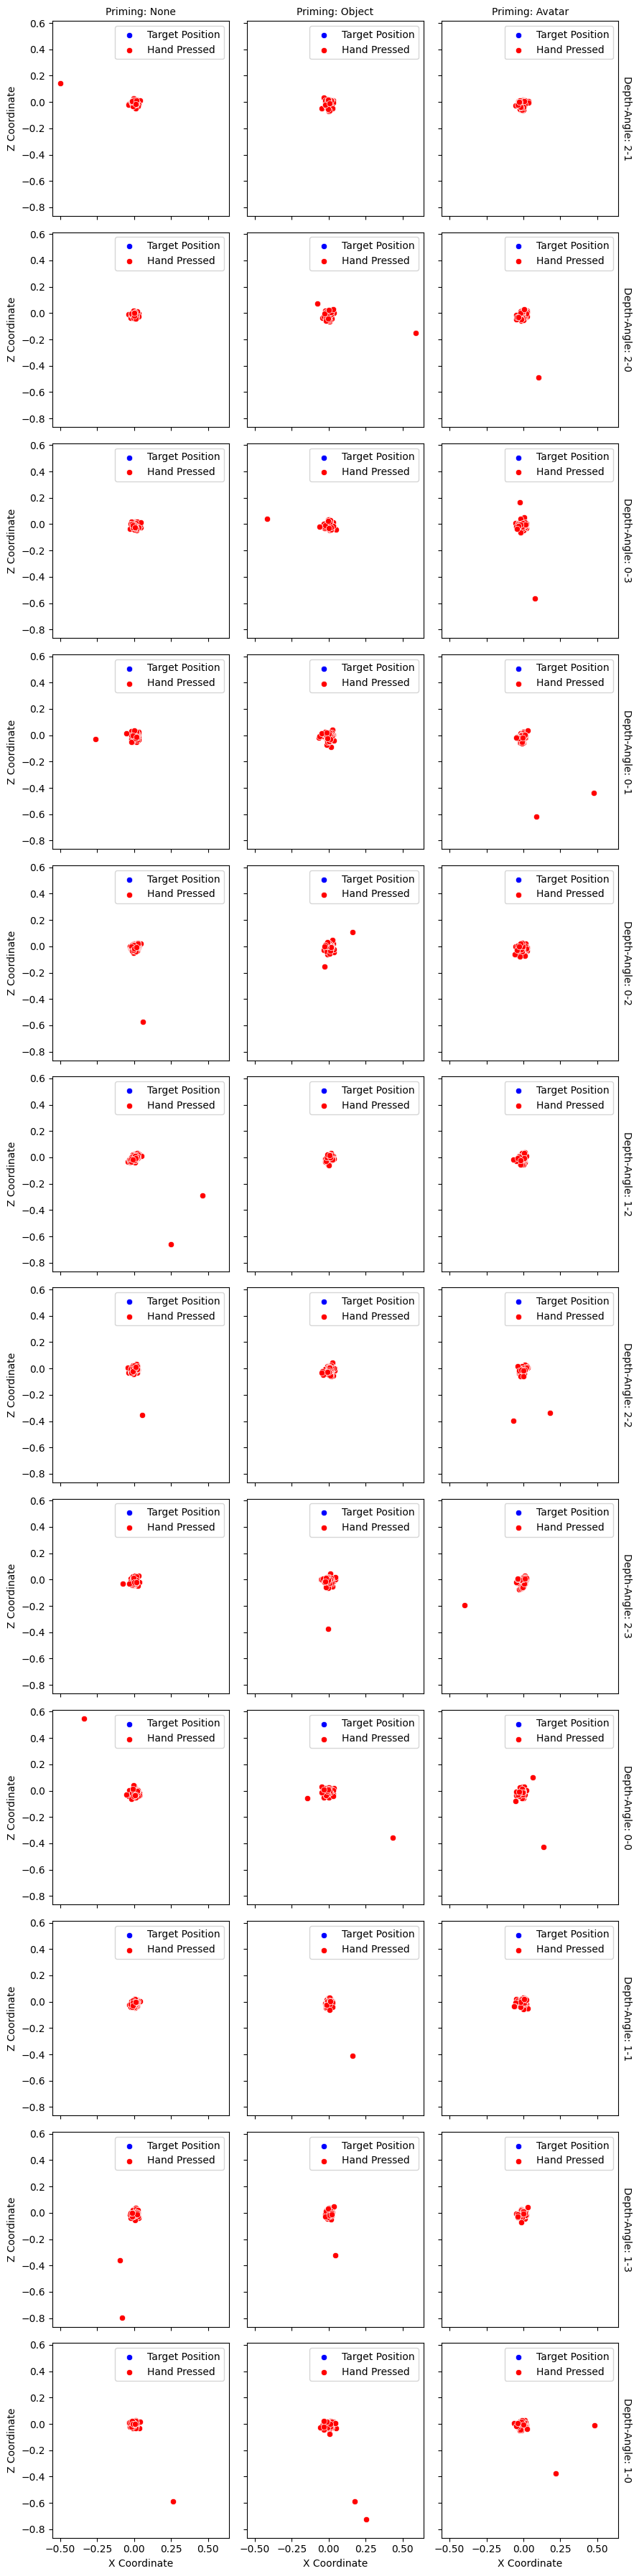

In [50]:


# Create a new column for combined DepthSection and AngleSection
final_translate_newdf['Section'] = final_translate_newdf['DepthSection'].astype(str) + '-' + final_translate_newdf['AngleSection'].astype(str)

# FacetGrid for plotting
g = sns.FacetGrid(final_translate_newdf, col='Priming Type', row='Section', margin_titles=True, despine=False)
g.map_dataframe(sns.scatterplot, x='TargetPosX_Trans', y='TargetPosZ_Trans', color='blue', label='Target Position')
g.map_dataframe(sns.scatterplot, x='HandPressedX_Rel', y='HandPressedZ_Rel', color='red', label='Hand Pressed')

# Add legend
for ax in g.axes.flat:
    ax.legend(loc='best')

# Set titles and labels
g.set_axis_labels("X Coordinate", "Z Coordinate")
g.set_titles(row_template="Depth-Angle: {row_name}", col_template="Priming: {col_name}")
g.tight_layout()

plt.show()


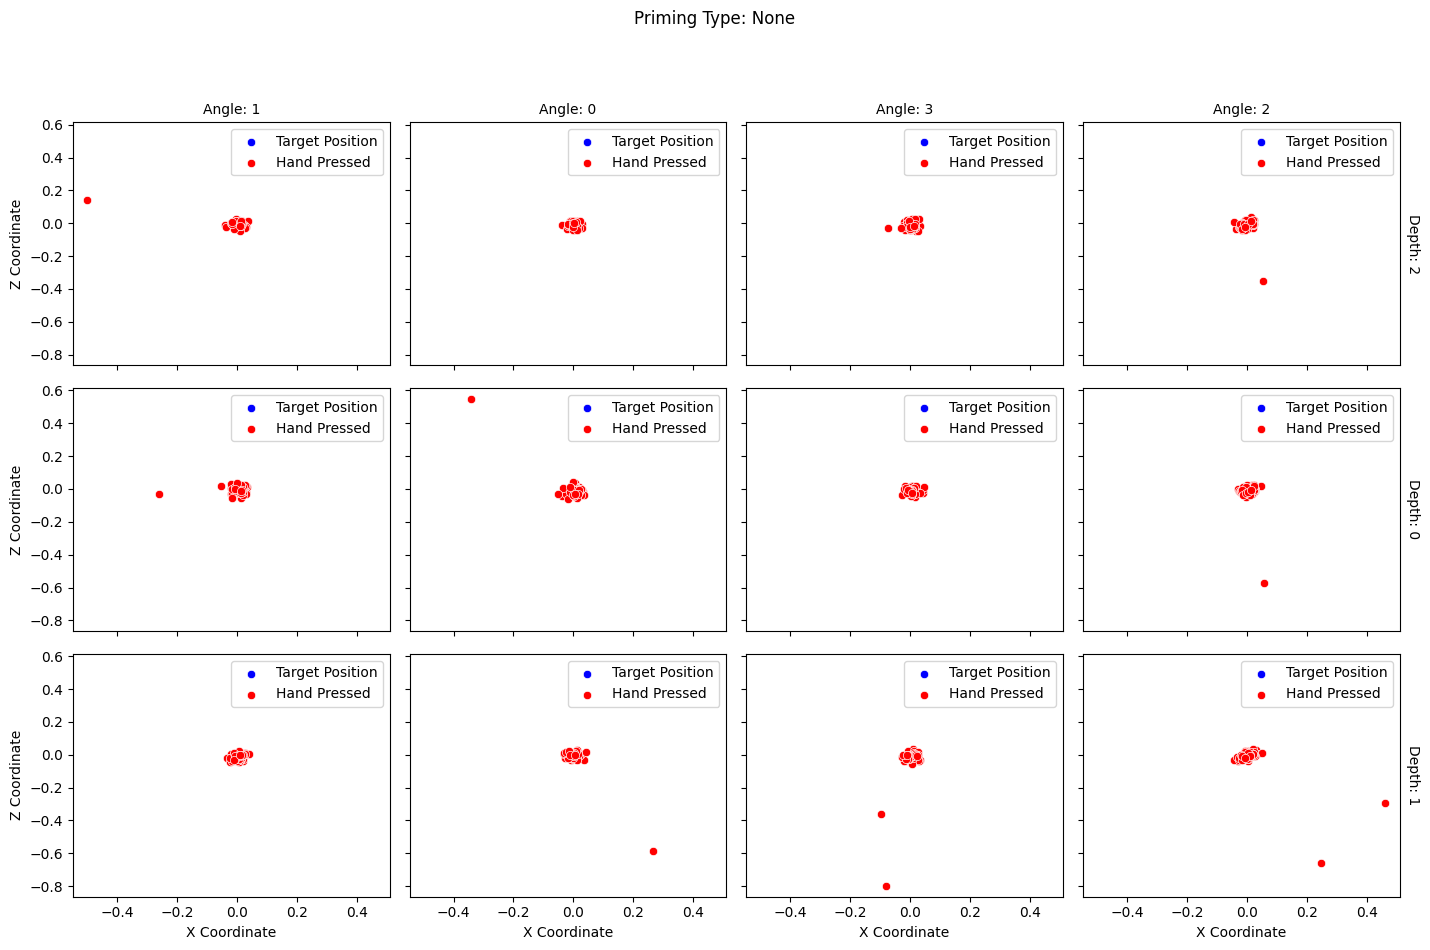

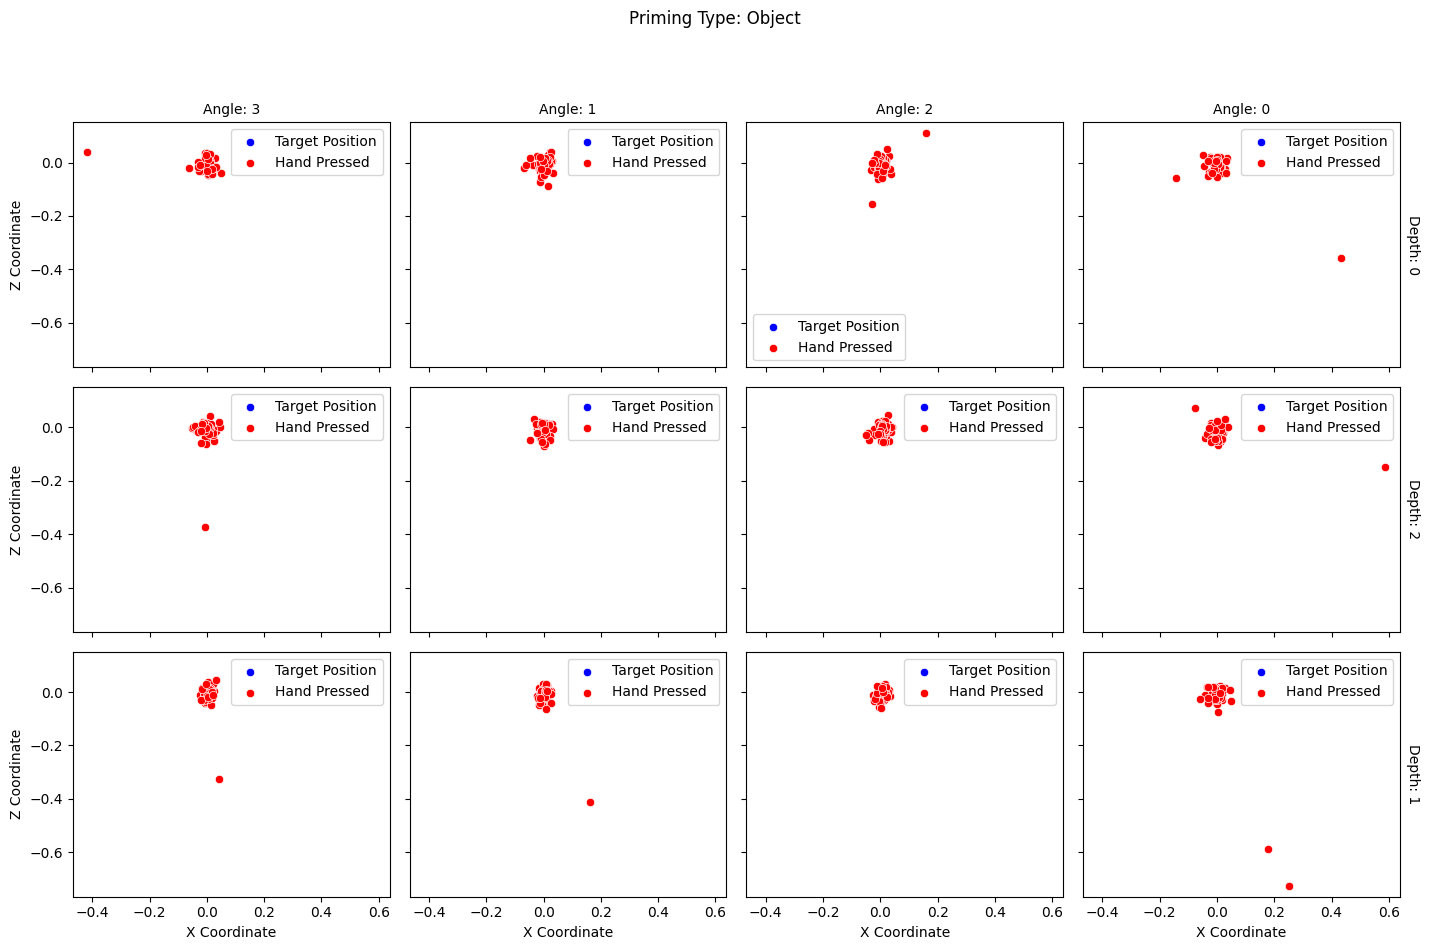

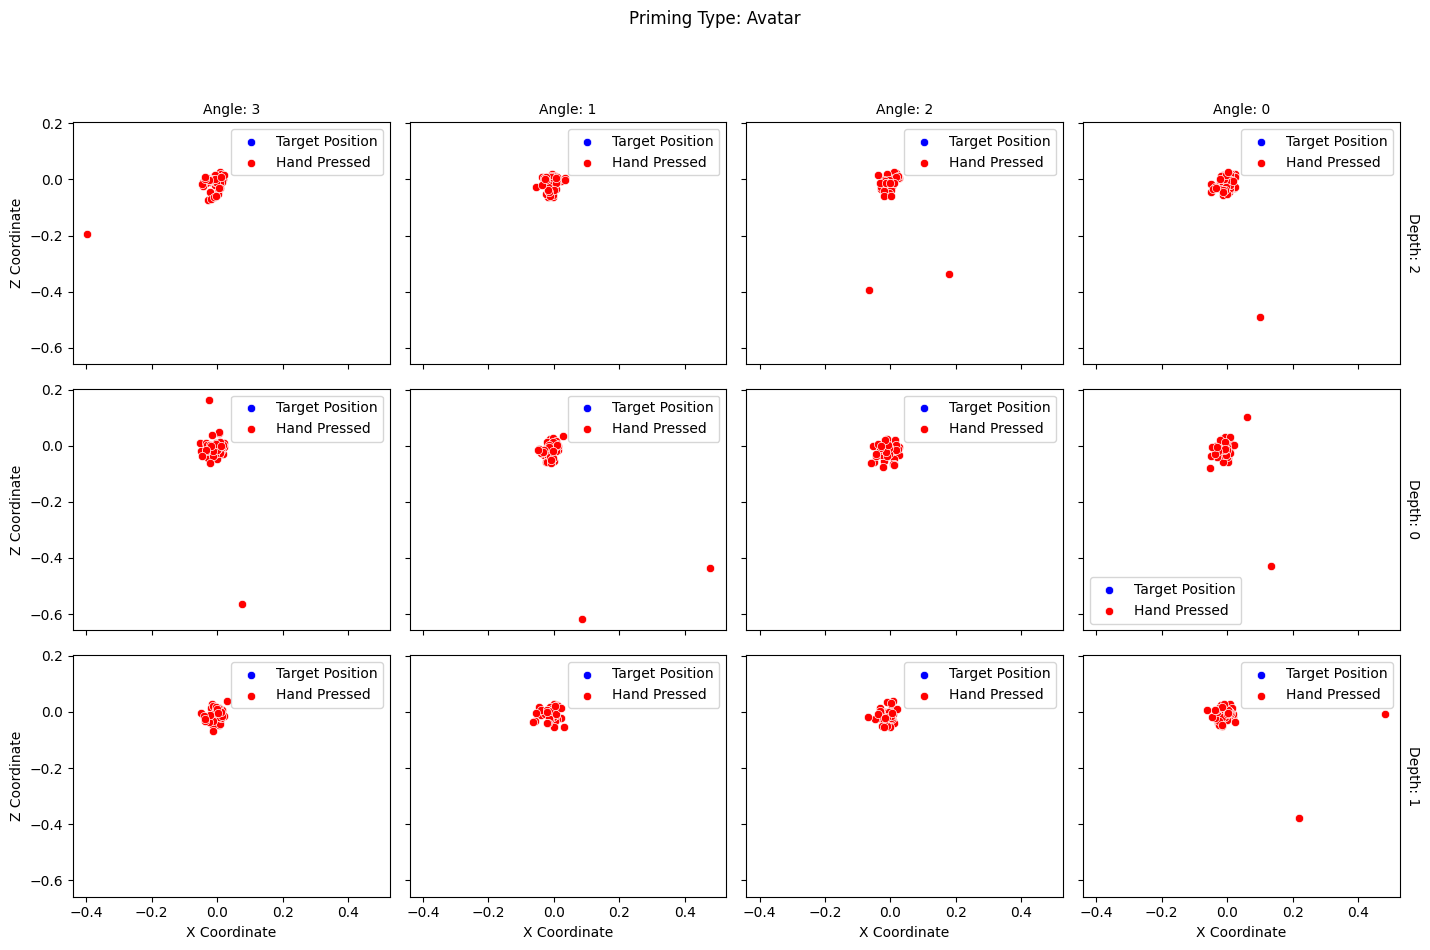

In [ ]:

# Create scatter grid plots for each Priming Type
priming_types = final_translate_newdf['Priming Type'].unique()

#g.map_dataframe(sns.scatterplot, x='TargetPosX_Trans', y='TargetPosZ_Trans', color='blue', label='Target Position')
# g.map_dataframe(sns.scatterplot, x='HandPressedX_Rel', y='HandPressedZ_Rel', color='red', label='Hand Pressed')
 

for priming in priming_types:
    priming_df = final_translate_newdf[final_translate_newdf['Priming Type'] == priming]  # Filter data for the current priming type

    # Create scatter grid with DepthSection and AngleSection
    g = sns.FacetGrid(
        priming_df, 
        row="DepthSection", 
        col="AngleSection", 
        margin_titles=True, 
        despine=False, 
        height=3, 
        aspect=1.2
    )

    # Scatter plots for Target and Hand Pressed positions
    g.map_dataframe(
        sns.scatterplot, 
        x="TargetPosX_Trans", 
        y="TargetPosZ_Trans", 
        color="blue", 
        label="Target Position"
    )
    g.map_dataframe(
        sns.scatterplot, 
        x="HandPressedX_Rel", 
        y="HandPressedZ_Rel", 
        color="red", 
        label="Hand Pressed"
    )

    # Add legend to each subplot
    for ax in g.axes.flat:
        ax.legend(loc="best")

    # Set common labels and titles
    g.set_axis_labels("X Coordinate", "Z Coordinate")
    g.set_titles(row_template="Depth: {row_name}", col_template="Angle: {col_name}")
    g.fig.suptitle(f"Priming Type: {priming}", y=1.05)  # Add a super title for each grid
    g.tight_layout()

    # Show the plot for the current Priming Type
    plt.show()


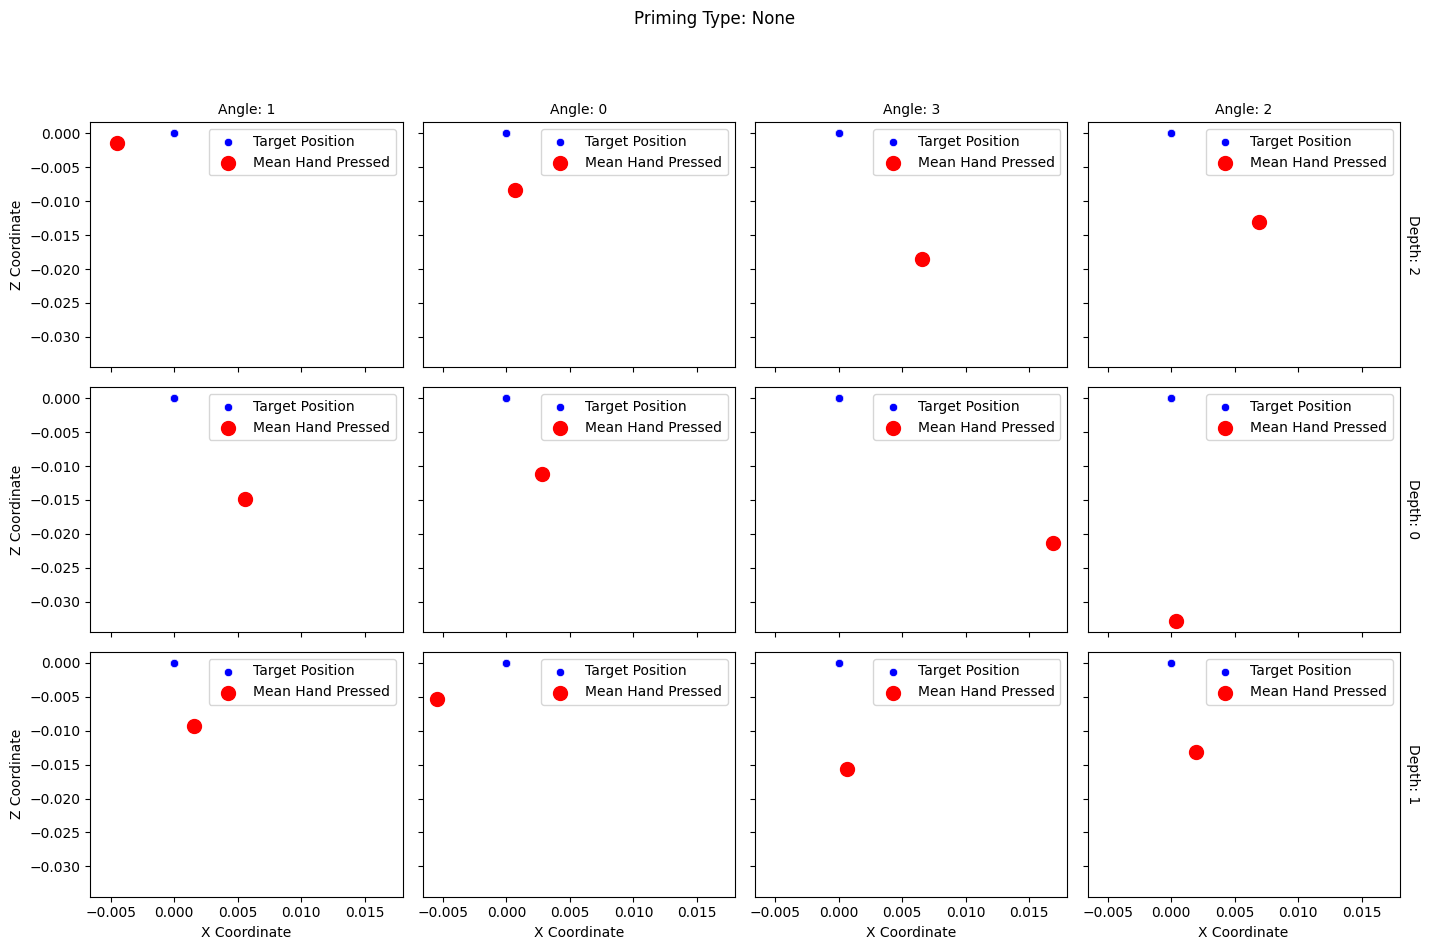

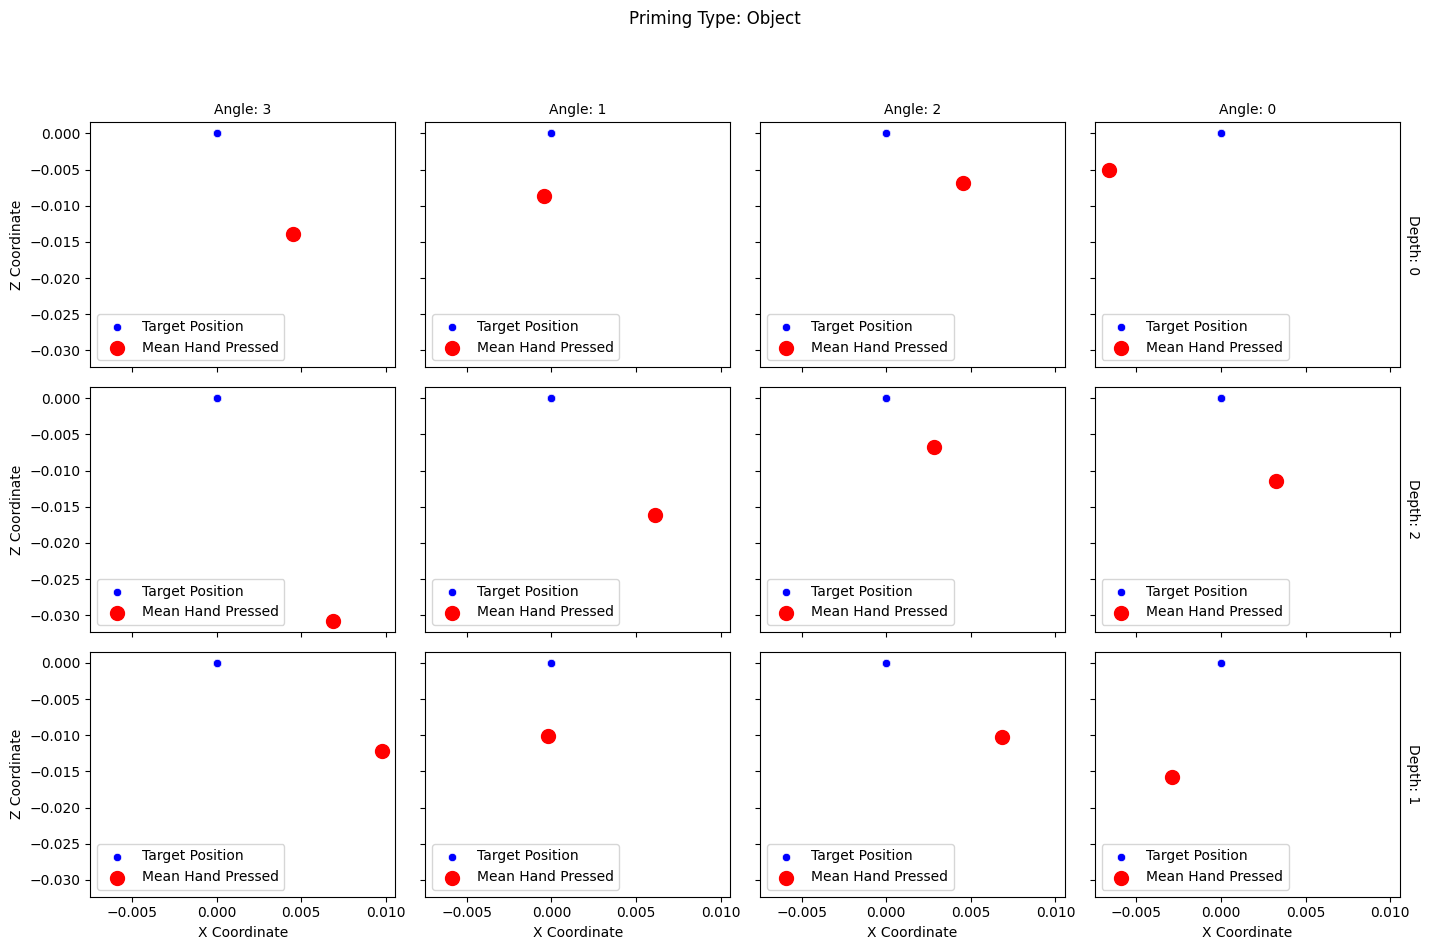

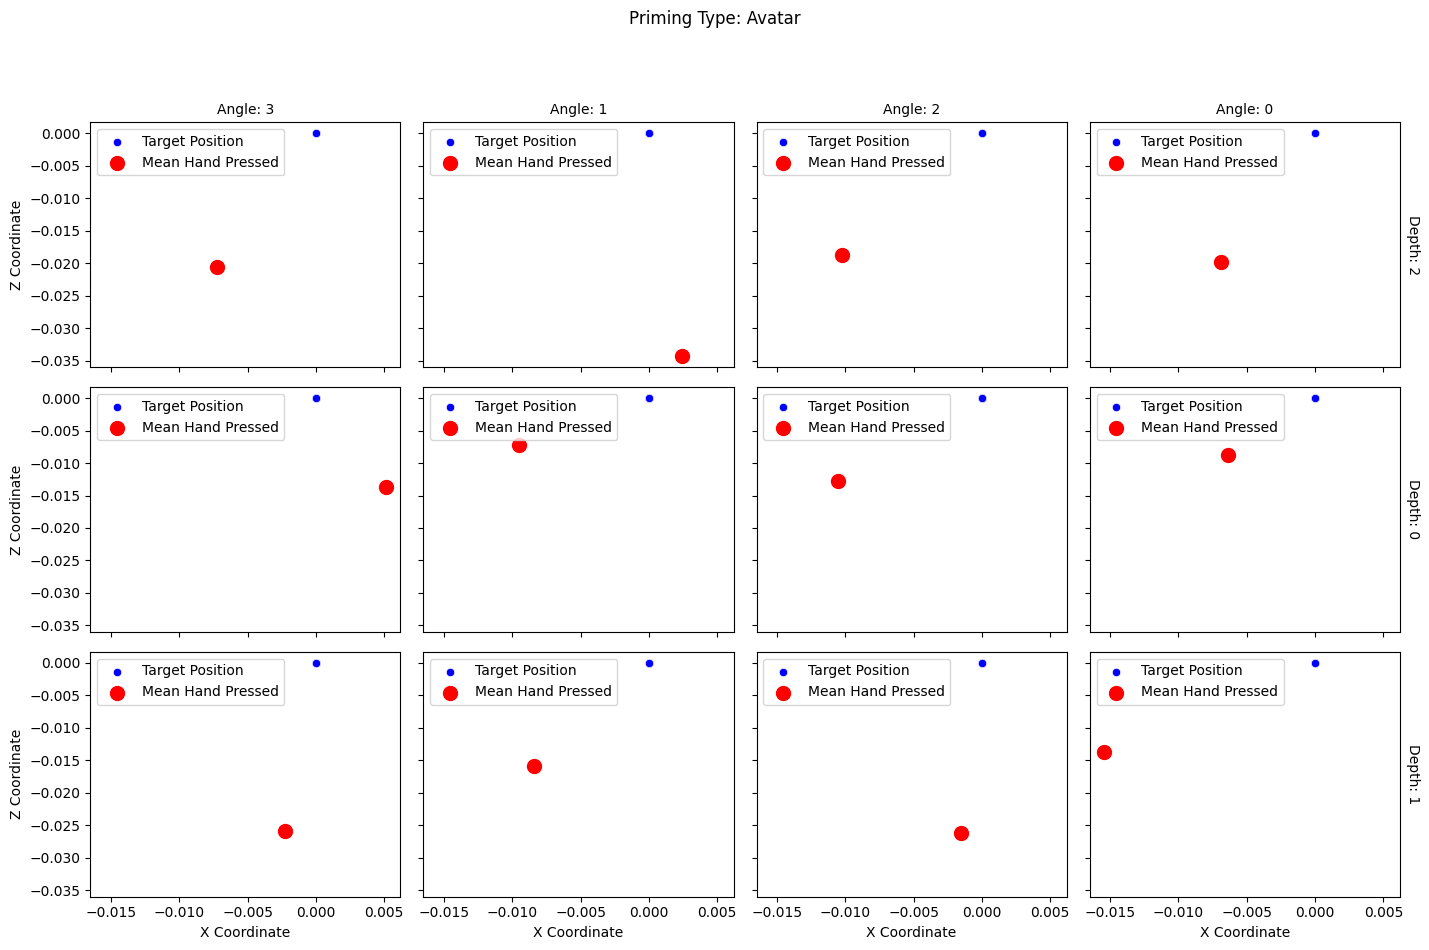

In [73]:
# Create scatter grid plots for each Priming Type
priming_types = final_translate_newdf['Priming Type'].unique()

for priming in priming_types:
    # Filter data for the current priming type
    priming_df = final_translate_newdf[final_translate_newdf['Priming Type'] == priming]
    
    # Calculate mean hand-pressed positions for each DepthSection-AngleSection combination
    mean_handpressed_df = (
        priming_df.groupby(['DepthSection', 'AngleSection'], as_index=False)
        .agg({'HandPressedX_Rel': 'mean', 'HandPressedZ_Rel': 'mean'})
    )
    
    # Create scatter grid with DepthSection and AngleSection
    g = sns.FacetGrid(
        priming_df, 
        row="DepthSection", 
        col="AngleSection", 
        margin_titles=True, 
        despine=False, 
        height=3, 
        aspect=1.2
    )

    # Plot Target positions (scatterplot for all points)
    g.map_dataframe(
        sns.scatterplot, 
        x="TargetPosX_Trans", 
        y="TargetPosZ_Trans", 
        color="blue", 
        label="Target Position"
    )

    # Plot mean hand-pressed position (one dot per grid cell)
    for ax, (_, sub_df) in zip(g.axes.flat, mean_handpressed_df.iterrows()):
        ax.scatter(
            sub_df["HandPressedX_Rel"], 
            sub_df["HandPressedZ_Rel"], 
            color="red", 
            s=100, 
            label="Mean Hand Pressed"
        )

    # Add legend to each subplot
    for ax in g.axes.flat:
        ax.legend(loc="best")

    # Set common labels and titles
    g.set_axis_labels("X Coordinate", "Z Coordinate")
    g.set_titles(row_template="Depth: {row_name}", col_template="Angle: {col_name}")
    g.fig.suptitle(f"Priming Type: {priming}", y=1.05)  # Add a super title for each grid
    g.tight_layout()

    # Show the plot for the current Priming Type
    plt.show()


KeyError: "None of [Index([(0,), (0,)], dtype='object', name=0)] are in the [columns]"

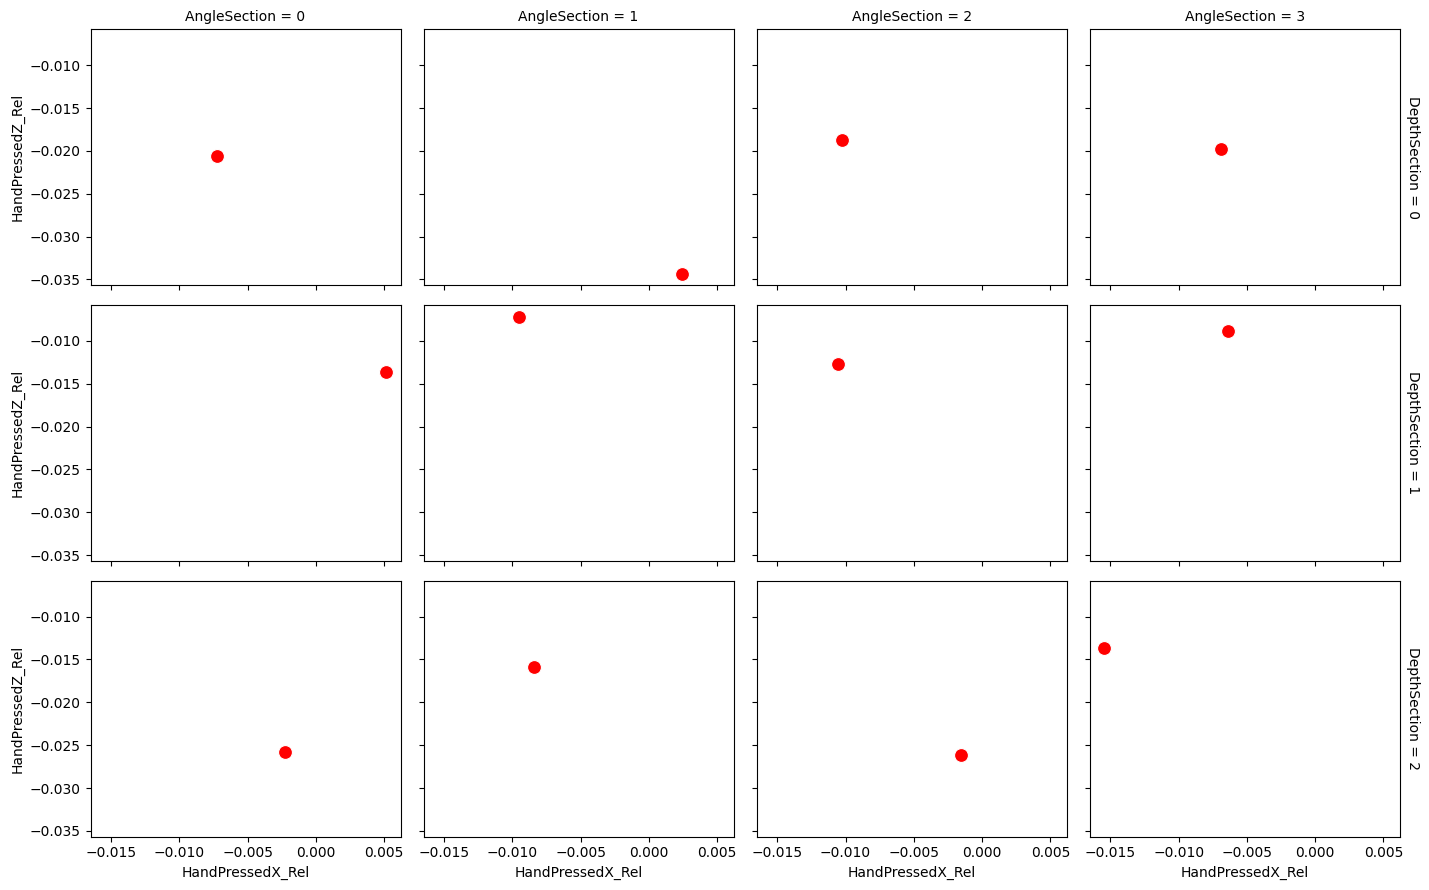

In [72]:

# Compute the mean of HandPressedX and HandPressedZ grouped by Priming Type, DepthSection, and AngleSection

#g.map_dataframe(sns.scatterplot, x='TargetPosX_Trans', y='TargetPosZ_Trans', color='blue', label='Target Position')
# g.map_dataframe(sns.scatterplot, x='HandPressedX_Rel', y='HandPressedZ_Rel', color='red', label='Hand Pressed')


mean_df = (
    final_translate_newdf.groupby(['Priming Type', 'DepthSection', 'AngleSection'], as_index=False)
    .agg({'HandPressedX_Rel': 'mean', 'HandPressedZ_Rel': 'mean'})
)

# Plot scatter grid for each Priming Type
priming_types = mean_df['Priming Type'].unique()

for priming in priming_types:
    priming_df = mean_df[mean_df['Priming Type'] == priming]  # Filter data for the current priming type

    # Create scatter grid with DepthSection and AngleSection
    g = sns.FacetGrid(
        priming_df, 
        row="DepthSection", 
        col="AngleSection", 
        margin_titles=True, 
        despine=False, 
        height=3, 
        aspect=1.2
    )

    # Plot the mean hand-pressed positions
    g.map_dataframe(
        sns.scatterplot, 
        x="HandPressedX_Rel", 
        y="HandPressedZ_Rel", 
        color="red", 
        s=100, 
        label="Mean Hand Position"
    )

    # Add target position (0, 0) as a reference point
    g.map(plt.scatter, [0], [0], color="blue", s=100, label="Target Position")

    # Add legend to each subplot
    for ax in g.axes.flat:
        ax.legend(loc="best")

    # Set labels and titles
    g.set_axis_labels("X Coordinate", "Z Coordinate")
    g.set_titles(row_template="Depth: {row_name}", col_template="Angle: {col_name}")
    g.fig.suptitle(f"Priming Type: {priming}", y=1.05)  # Add a super title for each grid
    g.tight_layout()

    # Show the plot for the current Priming Type
    plt.show()


In [15]:
import matplotlib.pyplot as plt
import pandas as pd

# 2D Scatter Plot of Translated Traget of postions and relative Hand Pressed

# Use Case: Visualizes how target positions relate to actual hand-pressed positions spatially.


C:\Users\VR1\AppData\Local\Temp\ipykernel_24076\4079108361.py:66: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_unique[col] = pd.to_numeric(df_unique[col], errors='coerce')
C:\Users\VR1\AppData\Local\Temp\ipykernel_24076\4079108361.py:69: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_unique['TargetPosX_Trans'] = 0
C:\Users\VR1\AppData\Local\Temp\ipykernel_24076\4079108361.py:70: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_i


Processed Translated Data (New DataFrame):


C:\Users\VR1\AppData\Local\Temp\ipykernel_24076\4079108361.py:66: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_unique[col] = pd.to_numeric(df_unique[col], errors='coerce')
C:\Users\VR1\AppData\Local\Temp\ipykernel_24076\4079108361.py:69: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_unique['TargetPosX_Trans'] = 0
C:\Users\VR1\AppData\Local\Temp\ipykernel_24076\4079108361.py:70: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_i

,ID,Priming Type,DepthSection,AngleSection,TargetPosX_Trans,TargetPosZ_Trans,HandPressedX_Rel,HandPressedZ_Rel
0,ID : 11,None,2,1,0,0,-0.498663,0.142908
1,ID : 11,None,2,1,0,0,0.003800,-0.025868
2,ID : 11,None,2,1,0,0,-0.008120,-0.005218
3,ID : 11,None,2,1,0,0,-0.005888,-0.005476
4,ID : 11,None,2,1,0,0,-0.010304,-0.000050
...,...,...,...,...,...,...,...,...
2008,ID : 20,Avatar,2,3,0,0,-0.042980,-0.024638
2009,ID : 20,Avatar,2,3,0,0,0.012087,0.008999
2010,ID : 20,Avatar,2,3,0,0,-0.047756,-0.017818
2011,ID : 20,Avatar,2,3,0,0,-0.037517,0.002803


Processed data saved to: C:\Users\VR1\Documents\filtered_combined_data.csv


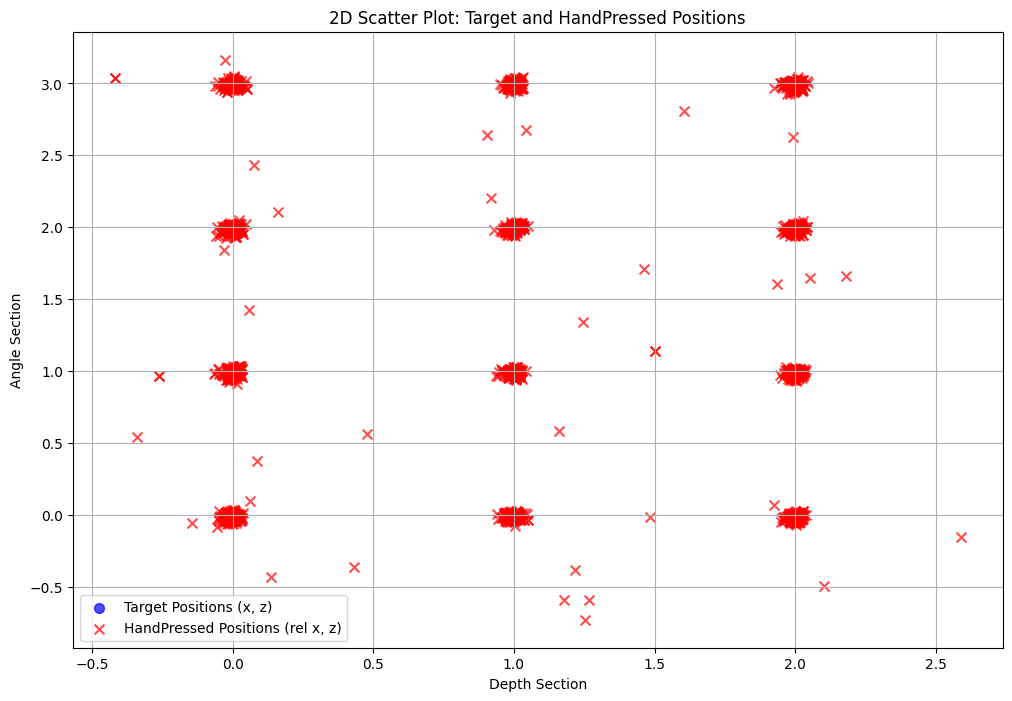

In [49]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Define the folder path containing the CSV files
folder_path = r"C:\Users\VR1\Documents\CSV 180"

# Function to extract metadata from each VR summary file
def extract_vr_summary_data(file_path):
    """Extracts relevant fields from a VR summary CSV."""
    data = pd.read_csv(file_path, header=None)
    summary = {}

    for _, row in data.iterrows():
        row_str = str(row[0])
        if "ID" in row_str:
            summary["ID"] = row_str.split('=')[-1].strip()
        elif "Priming type" in row_str:
            summary["Priming Type"] = row_str.split('=')[-1].strip()

    return summary

# Initialize lists for metadata and real data
metadata_list = []
data_list = []

# Process each CSV file in the folder
for file_name in os.listdir(folder_path):
    if file_name.endswith('.csv'):
        file_path = os.path.join(folder_path, file_name)

        # Extract metadata
        metadata = extract_vr_summary_data(file_path)
        metadata_list.append(metadata)

        # Extract real data (starting from the 9th row)
        final_data = pd.read_csv(file_path, skiprows=8, header=None)
        
        # Ensure the first column contains strings before applying string operations
        final_data[0] = final_data[0].astype(str).str.strip().replace(r'\s+', ' ', regex=True)

        # Split the column into multiple columns based on spaces
        df_split = final_data[0].str.split(" ", expand=True)
        df_split.columns = df_split.iloc[0]  # Set column names from the first row
        df_split = df_split[1:]  # Remove the header row

        # Check if required columns exist
        required_columns = ['TargetPosX', 'TargetPosZ', 'HandPressedX', 'HandPressedZ', 
                            'DepthSection', 'AngleSection']
        missing_columns = [col for col in required_columns if col not in df_split.columns]

        if missing_columns:
            print(f"Warning: Missing columns {missing_columns} in file {file_name}. Skipping...")
            continue

        # Drop duplicates based on 'PressedHandCounter' if available
        if 'PressedHandCounter' in df_split.columns:
            df_unique = df_split.drop_duplicates(subset='PressedHandCounter', keep='first')
        else:
            df_unique = df_split.copy()

        # Ensure numeric columns are converted
        for col in ['TargetPosX', 'TargetPosZ', 'HandPressedX', 'HandPressedZ']:
            df_unique[col] = pd.to_numeric(df_unique[col], errors='coerce')

        # Translate TargetPosX and TargetPosZ to (0, 0)
        df_unique['TargetPosX_Trans'] = 0
        df_unique['TargetPosZ_Trans'] = 0

        # Adjust HandPressedX and HandPressedZ relative to TargetPosX and TargetPosZ
        df_unique['HandPressedX_Rel'] = df_unique['HandPressedX'] - df_unique['TargetPosX']
        df_unique['HandPressedZ_Rel'] = df_unique['HandPressedZ'] - df_unique['TargetPosZ']

        # Create a new DataFrame with required columns
        translate_newdf = df_unique[[ 
            'DepthSection', 'AngleSection', 
            'TargetPosX_Trans', 'TargetPosZ_Trans', 
            'HandPressedX_Rel', 'HandPressedZ_Rel'
        ]].copy()

        # Add metadata columns
        translate_newdf['ID'] = metadata.get("ID", None)
        translate_newdf['Priming Type'] = metadata.get("Priming Type", None)

        # Reorder columns for clarity
        translate_newdf = translate_newdf[[ 
            'ID', 'Priming Type', 'DepthSection', 'AngleSection', 
            'TargetPosX_Trans', 'TargetPosZ_Trans', 'HandPressedX_Rel', 'HandPressedZ_Rel'
        ]]

        # Append processed data
        data_list.append(translate_newdf)

# Combine all translated data into a single DataFrame
final_translate_newdf = pd.concat(data_list, ignore_index=True)

# Display results
print("\nProcessed Translated Data (New DataFrame):")
display(final_translate_newdf)

# Define the new folder path
new_folder_path = r"C:\Users\VR1\Documents"

# Ensure the new folder exists; if not, create it
os.makedirs(new_folder_path, exist_ok=True)

# Define the output path in the new folder
output_path = os.path.join(new_folder_path, "filtered_combined_data.csv")

# Save the filtered data to the new folder
final_df.to_csv(output_path, index=False)

# Print confirmation of where the file is saved
print(f"Processed data saved to: {output_path}")

# --------------------------- Plotting Section ---------------------------
# Ensure numeric conversion for plotting
final_translate_newdf['DepthSection'] = pd.to_numeric(final_translate_newdf['DepthSection'], errors='coerce')
final_translate_newdf['AngleSection'] = pd.to_numeric(final_translate_newdf['AngleSection'], errors='coerce')

# Plotting
plt.figure(figsize=(12, 8))

# Plot Target Positions (Translated)
plt.scatter(final_translate_newdf['DepthSection'], final_translate_newdf['AngleSection'], 
            color='blue', label='Target Positions (x, z)', s=50, alpha=0.7)

# Plot HandPressed Positions (Relative)
plt.scatter(final_translate_newdf['DepthSection'] + final_translate_newdf['HandPressedX_Rel'], 
            final_translate_newdf['AngleSection'] + final_translate_newdf['HandPressedZ_Rel'], 
            color='red', marker='x', label='HandPressed Positions (rel x, z)', s=50, alpha=0.7)

# Add labels and grid
plt.title("2D Scatter Plot: Target and HandPressed Positions")
plt.xlabel("Depth Section")
plt.ylabel("Angle Section")
plt.grid(True)
plt.legend()
plt.show()


C:\Users\VR1\AppData\Local\Temp\ipykernel_24076\3342379399.py:56: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_unique[col] = pd.to_numeric(df_unique[col], errors='coerce')
C:\Users\VR1\AppData\Local\Temp\ipykernel_24076\3342379399.py:58: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_unique['TargetPosX_Trans'] = 0
C:\Users\VR1\AppData\Local\Temp\ipykernel_24076\3342379399.py:59: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_i

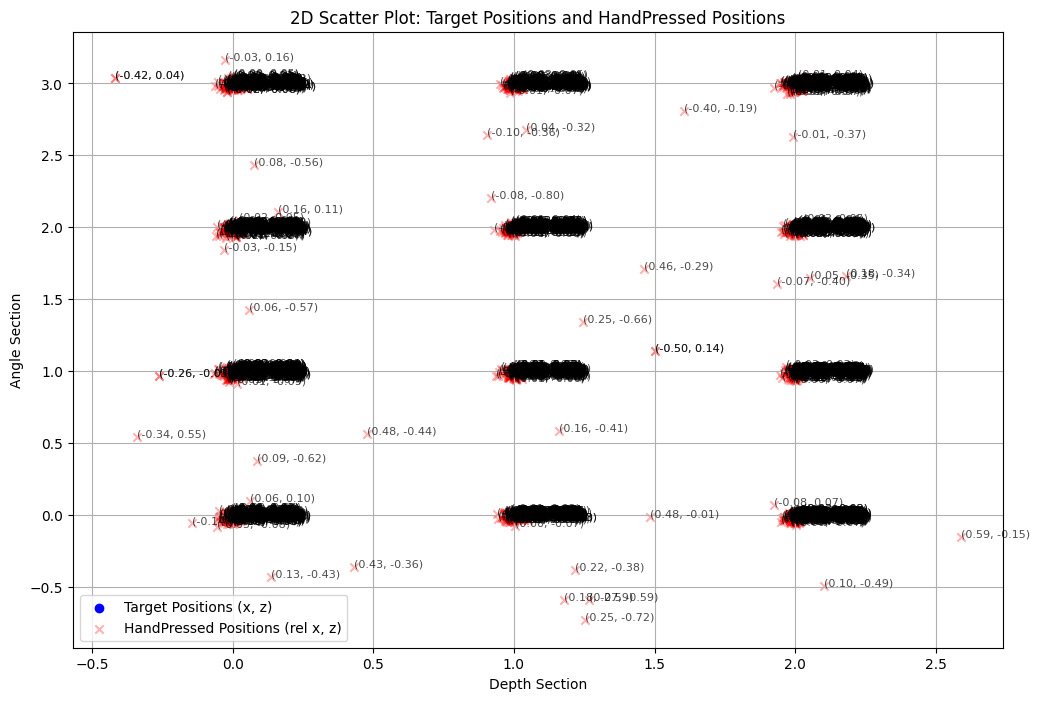

In [50]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Define the folder path containing the CSV files
folder_path = r"C:\Users\VR1\Documents\CSV 180"

# Function to extract metadata from each VR summary file
def extract_vr_summary_data(file_path):
    """Extracts relevant fields from a VR summary CSV."""
    data = pd.read_csv(file_path, header=None)
    summary = {}

    for _, row in data.iterrows():
        row_str = str(row[0])
        if "ID" in row_str:
            summary["ID"] = row_str.split('=')[-1].strip()
        elif "Priming type" in row_str:
            summary["Priming Type"] = row_str.split('=')[-1].strip()

    return summary

# Initialize lists for metadata and real data
metadata_list = []
data_list = []

# Process each CSV file in the folder
for file_name in os.listdir(folder_path):
    if file_name.endswith('.csv'):
        file_path = os.path.join(folder_path, file_name)

        # Extract metadata
        metadata = extract_vr_summary_data(file_path)

        # Extract real data (starting from the 9th row)
        final_data = pd.read_csv(file_path, skiprows=8, header=None)
        final_data[0] = final_data[0].astype(str).str.strip().replace(r'\s+', ' ', regex=True)

        df_split = final_data[0].str.split(" ", expand=True)
        df_split.columns = df_split.iloc[0]
        df_split = df_split[1:]

        required_columns = ['TargetPosX', 'TargetPosZ', 'HandPressedX', 'HandPressedZ', 
                            'DepthSection', 'AngleSection']
        if not all(col in df_split.columns for col in required_columns):
            continue

        # Drop duplicates
        if 'PressedHandCounter' in df_split.columns:
            df_unique = df_split.drop_duplicates(subset='PressedHandCounter', keep='first')
        else:
            df_unique = df_split.copy()

        # Convert to numeric
        for col in ['TargetPosX', 'TargetPosZ', 'HandPressedX', 'HandPressedZ']:
            df_unique[col] = pd.to_numeric(df_unique[col], errors='coerce')

        df_unique['TargetPosX_Trans'] = 0
        df_unique['TargetPosZ_Trans'] = 0

        # Relative HandPressed positions
        df_unique['HandPressedX_Rel'] = df_unique['HandPressedX'] - df_unique['TargetPosX']
        df_unique['HandPressedZ_Rel'] = df_unique['HandPressedZ'] - df_unique['TargetPosZ']

        # Final DataFrame
        translate_newdf = df_unique[[
            'DepthSection', 'AngleSection', 
            'TargetPosX_Trans', 'TargetPosZ_Trans', 
            'HandPressedX_Rel', 'HandPressedZ_Rel'
        ]].copy()

        # Add metadata
        translate_newdf['ID'] = metadata.get("ID", None)
        translate_newdf['Priming Type'] = metadata.get("Priming Type", None)

        translate_newdf = translate_newdf[[
            'ID', 'Priming Type', 'DepthSection', 'AngleSection', 
            'TargetPosX_Trans', 'TargetPosZ_Trans', 'HandPressedX_Rel', 'HandPressedZ_Rel'
        ]]
        data_list.append(translate_newdf)

# Combine all translated data
final_translate_newdf = pd.concat(data_list, ignore_index=True)

# Convert DepthSection and AngleSection to numeric for plotting
final_translate_newdf['DepthSection'] = pd.to_numeric(final_translate_newdf['DepthSection'], errors='coerce')
final_translate_newdf['AngleSection'] = pd.to_numeric(final_translate_newdf['AngleSection'], errors='coerce')

# Plotting
plt.figure(figsize=(12, 8))

# Plot Target Positions (Blue dots)
plt.scatter(final_translate_newdf['DepthSection'], final_translate_newdf['AngleSection'], 
            color='blue', label='Target Positions (x, z)', zorder=2)

# Plot Hand-Pressed Positions with Transparency (Red X's)
plt.scatter(final_translate_newdf['DepthSection'] + final_translate_newdf['HandPressedX_Rel'], 
            final_translate_newdf['AngleSection'] + final_translate_newdf['HandPressedZ_Rel'], 
            color='red', alpha=0.3, marker='x', label='HandPressed Positions (rel x, z)', zorder=1)

# Annotate hand-pressed values
for i, row in final_translate_newdf.iterrows():
    plt.text(row['DepthSection'] + row['HandPressedX_Rel'], 
             row['AngleSection'] + row['HandPressedZ_Rel'],
             f"({row['HandPressedX_Rel']:.2f}, {row['HandPressedZ_Rel']:.2f})", 
             fontsize=8, alpha=0.7)

# Labels and Title
plt.xlabel("Depth Section")
plt.ylabel("Angle Section")
plt.title("2D Scatter Plot: Target Positions and HandPressed Positions")
plt.legend()
plt.grid(True)

# Show the plot
plt.show()


# The scatter plots visualize target positions and hand-pressed positions in the VR environment, with all positional values represented in meters (m)

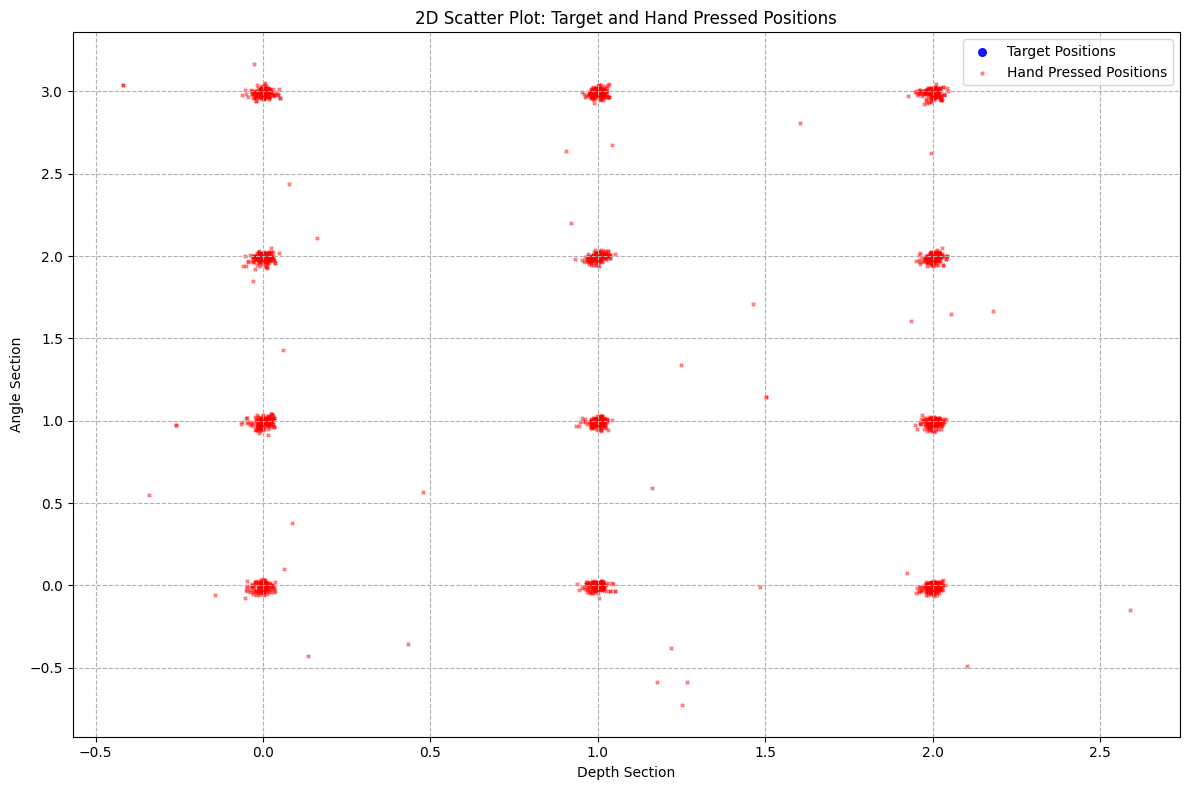

In [51]:

import matplotlib.pyplot as plt
import pandas as pd

# Assuming `final_translate_newdf` contains your processed data

# Ensure numeric conversion for plotting
final_translate_newdf['DepthSection'] = pd.to_numeric(final_translate_newdf['DepthSection'], errors='coerce')
final_translate_newdf['AngleSection'] = pd.to_numeric(final_translate_newdf['AngleSection'], errors='coerce')

# Create the scatter plot
plt.figure(figsize=(12, 8))  # Set figure size

# Scatter plot for target positions (shown as blue dots with high transparency)
plt.scatter(
    final_translate_newdf['DepthSection'], 
    final_translate_newdf['AngleSection'], 
    c='blue', 
    s=30, 
    alpha=0.9,  # Transparency level
    label="Target Positions"
)

# Scatter plot for hand-pressed positions (shown as red 'x' markers with higher transparency)
plt.scatter(
    final_translate_newdf['DepthSection'] + final_translate_newdf['HandPressedX_Rel'], 
    final_translate_newdf['AngleSection'] + final_translate_newdf['HandPressedZ_Rel'], 
    c='red', 
    s=5, 
    alpha=0.5,  # Adjust transparency
    marker='x', 
    label="Hand Pressed Positions"
)

# Customize plot appearance
plt.title("2D Scatter Plot: Target and Hand Pressed Positions")
plt.xlabel("Depth Section")
plt.ylabel("Angle Section")
plt.legend(loc='upper right')  # Add legend

# Add grid for better readability
plt.grid(True, linestyle='--', alpha=1)

# Remove data values from the plot for cleaner visualization
plt.tick_params(axis='both', which='major', labelsize=10)  # Customize tick labels
plt.tight_layout()  # Optimize layout

# Show the plot
plt.show()



# Average of Depth and Angle sections with Translated target and hand pressed 


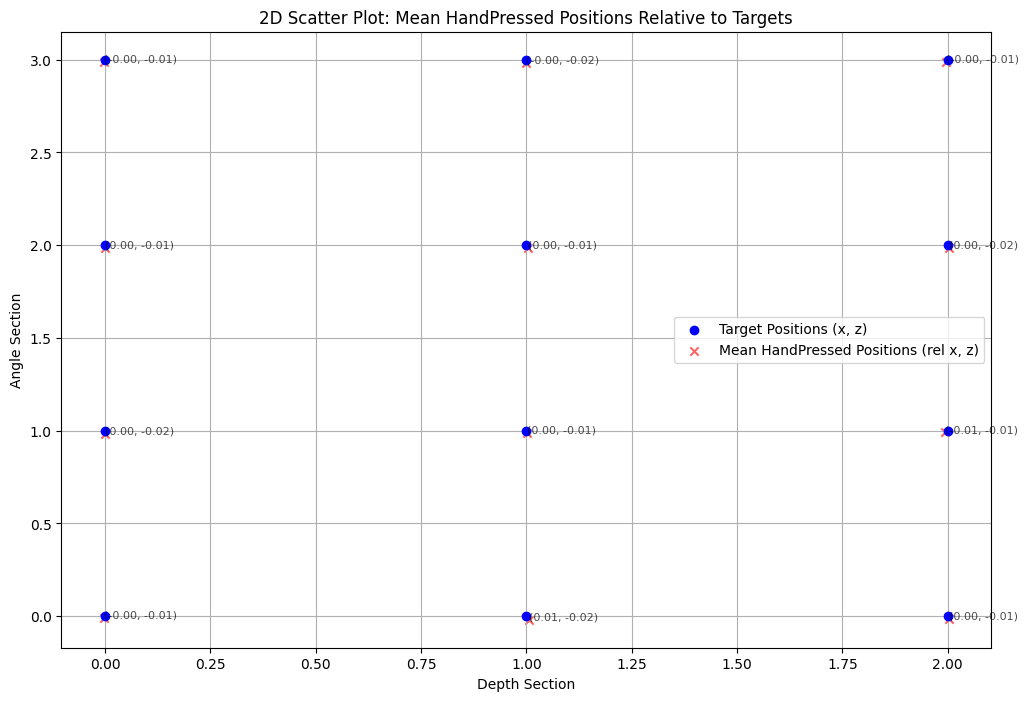

In [52]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Load and Process Data (Assuming `final_translate_newdf` already exists)
# If not, use your data processing code to create `final_translate_newdf`

# Ensure numeric conversion for DepthSection and AngleSection
final_translate_newdf['DepthSection'] = pd.to_numeric(final_translate_newdf['DepthSection'], errors='coerce')
final_translate_newdf['AngleSection'] = pd.to_numeric(final_translate_newdf['AngleSection'], errors='coerce')
final_translate_newdf['HandPressedX_Rel'] = pd.to_numeric(final_translate_newdf['HandPressedX_Rel'], errors='coerce')
final_translate_newdf['HandPressedZ_Rel'] = pd.to_numeric(final_translate_newdf['HandPressedZ_Rel'], errors='coerce')

# Grouping by DepthSection and AngleSection and calculating mean of hand-pressed positions
grouped_data = final_translate_newdf.groupby(['DepthSection', 'AngleSection']).agg({
    'HandPressedX_Rel': 'mean',
    'HandPressedZ_Rel': 'mean'
}).reset_index()

# Plotting
plt.figure(figsize=(12, 8))

# Plot Target Positions (Grouped by DepthSection and AngleSection)
plt.scatter(grouped_data['DepthSection'], grouped_data['AngleSection'], 
            color='blue', label='Target Positions (x, z)', zorder=2)

# Plot Mean Hand-Pressed Positions
plt.scatter(grouped_data['DepthSection'] + grouped_data['HandPressedX_Rel'], 
            grouped_data['AngleSection'] + grouped_data['HandPressedZ_Rel'], 
            color='red', alpha=0.6, marker='x', label='Mean HandPressed Positions (rel x, z)', zorder=1)

# Annotate Mean Hand-Pressed Values
for i, row in grouped_data.iterrows():
    plt.text(row['DepthSection'] + row['HandPressedX_Rel'], 
             row['AngleSection'] + row['HandPressedZ_Rel'],
             f"({row['HandPressedX_Rel']:.2f}, {row['HandPressedZ_Rel']:.2f})", 
             fontsize=8, alpha=0.7)

# Labels and Title
plt.xlabel("Depth Section")
plt.ylabel("Angle Section")
plt.title("2D Scatter Plot: Mean HandPressed Positions Relative to Targets")
plt.legend()
plt.grid(True)

# Show the plot
plt.show()


# HeatMap for translated target and handpressed relative 


# Use Case: Identifies areas (Depth & Angle sections) where the error is highest.

In [ ]:
pip install seaborn

# The heatmaps display the mean deviation of hand-pressed positions relative to targets, measured in meters (m) across different depth and angle sections (dimensionless)."

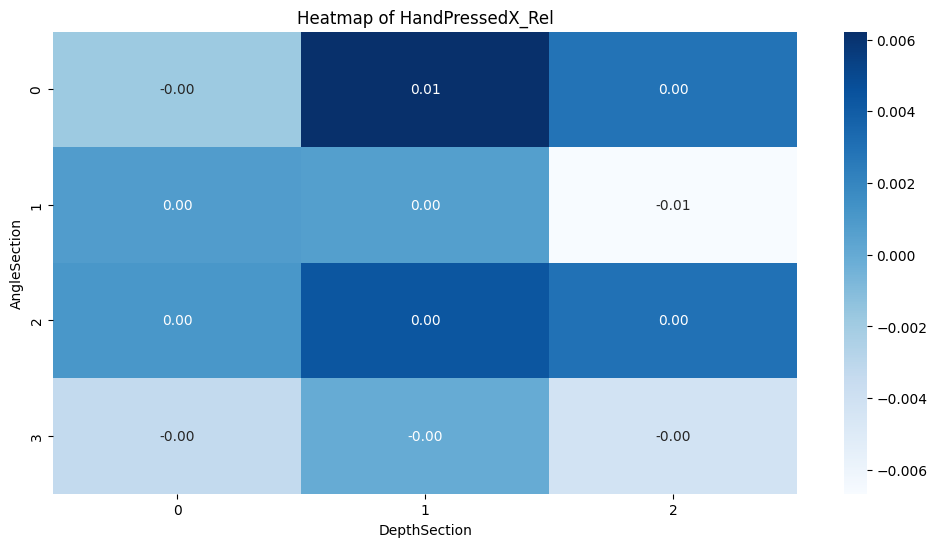

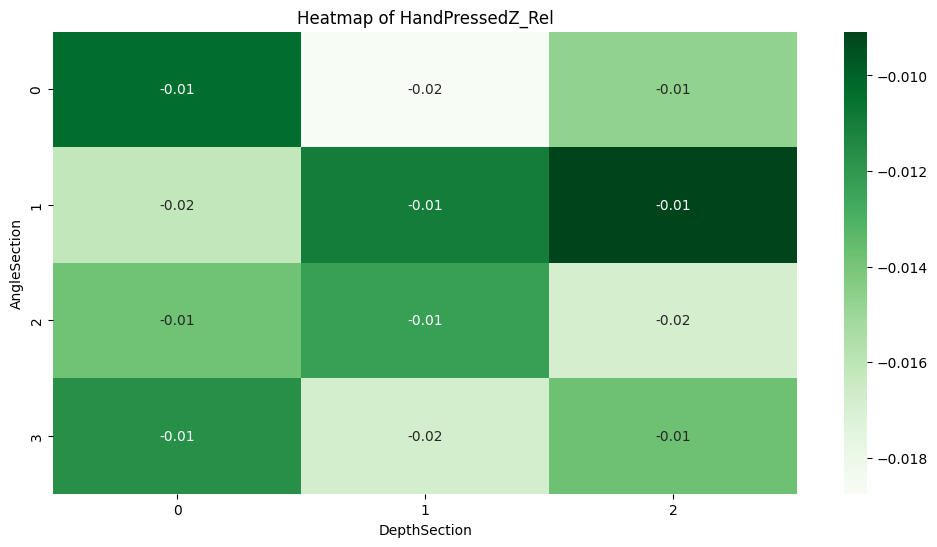

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Group data by DepthSection and AngleSection and calculate density/mean
heatmap_data = final_translate_newdf.groupby(['DepthSection', 'AngleSection']).agg({
    'HandPressedX_Rel': 'mean',
    'HandPressedZ_Rel': 'mean'
}).reset_index()

# Create pivot tables for heatmap
x_rel_pivot = heatmap_data.pivot(index='AngleSection', columns='DepthSection', values='HandPressedX_Rel')
z_rel_pivot = heatmap_data.pivot(index='AngleSection', columns='DepthSection', values='HandPressedZ_Rel')

# Plot HandPressedX_Rel Heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(x_rel_pivot, cmap="Blues", annot=True, fmt=".2f", cbar=True)
plt.title('Heatmap of HandPressedX_Rel')
plt.xlabel('DepthSection')
plt.ylabel('AngleSection')
plt.show()

# Plot HandPressedZ_Rel Heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(z_rel_pivot, cmap="Greens", annot=True, fmt=".2f", cbar=True)
plt.title('Heatmap of HandPressedZ_Rel')
plt.xlabel('DepthSection')
plt.ylabel('AngleSection')
plt.show()


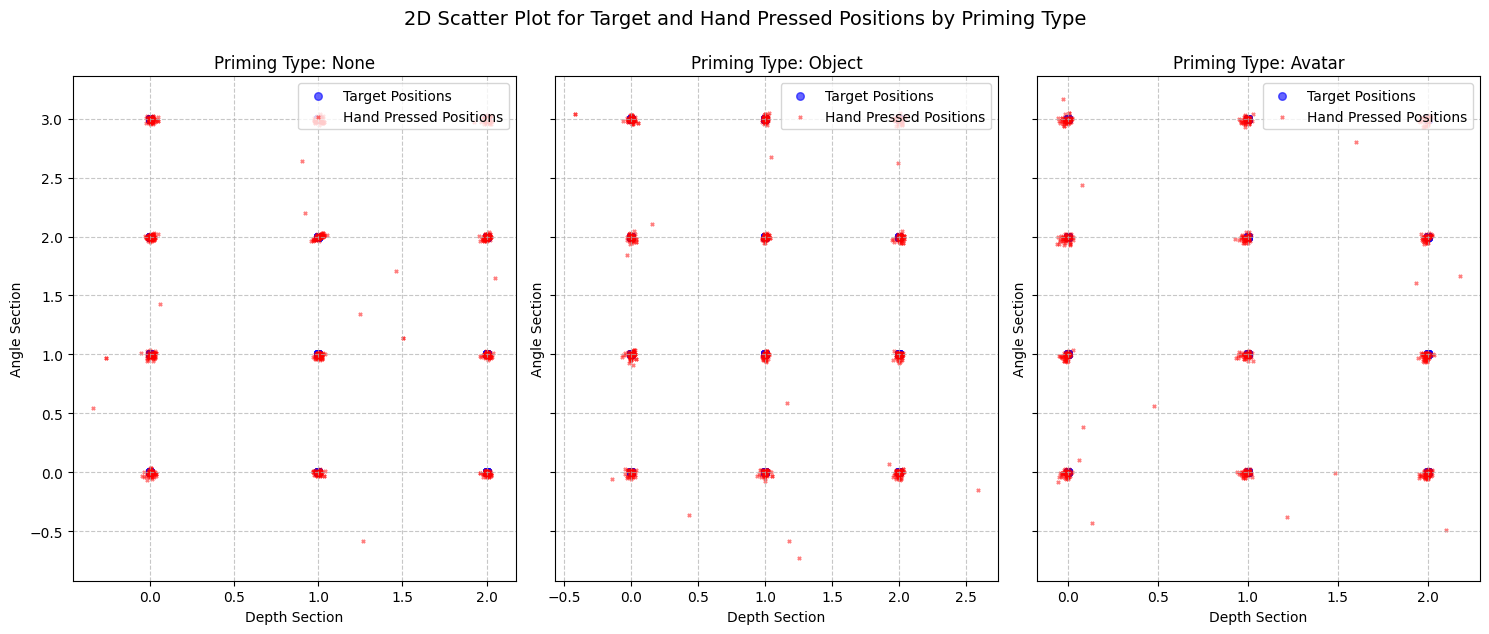

In [54]:
import matplotlib.pyplot as plt
import pandas as pd

# Assuming `final_translate_newdf` contains your processed data

# Ensure numeric conversion for plotting
final_translate_newdf['DepthSection'] = pd.to_numeric(final_translate_newdf['DepthSection'], errors='coerce')
final_translate_newdf['AngleSection'] = pd.to_numeric(final_translate_newdf['AngleSection'], errors='coerce')

# Check for the unique priming types
unique_priming_types = final_translate_newdf['Priming Type'].unique()

# Set up subplots: Create a grid layout for multiple plots
num_priming_types = len(unique_priming_types)
fig, axes = plt.subplots(1, num_priming_types, figsize=(15, 6), sharey=True)

# If there's only one priming type, `axes` won't be a list, so wrap it
if num_priming_types == 1:
    axes = [axes]

# Loop through each Priming Type and create a scatter plot
for ax, priming_type in zip(axes, unique_priming_types):
    # Filter data for the current Priming Type
    priming_data = final_translate_newdf[final_translate_newdf['Priming Type'] == priming_type]
    
    # Scatter plot for target positions
    ax.scatter(
        priming_data['DepthSection'],
        priming_data['AngleSection'],
        c='blue',
        s=30,
        alpha=0.6,
        label="Target Positions"
    )
    
    # Scatter plot for hand-pressed positions
    ax.scatter(
        priming_data['DepthSection'] + priming_data['HandPressedX_Rel'],
        priming_data['AngleSection'] + priming_data['HandPressedZ_Rel'],
        c='red',
        s=5,
        alpha=0.5,
        marker='x',
        label="Hand Pressed Positions"
    )
    
    # Set subplot title and labels
    ax.set_title(f"Priming Type: {priming_type}")
    ax.set_xlabel("Depth Section")
    ax.set_ylabel("Angle Section")
    ax.legend(loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.7)

# Adjust layout for better spacing
plt.tight_layout()
plt.suptitle("2D Scatter Plot for Target and Hand Pressed Positions by Priming Type", fontsize=14, y=1.05)
plt.show()


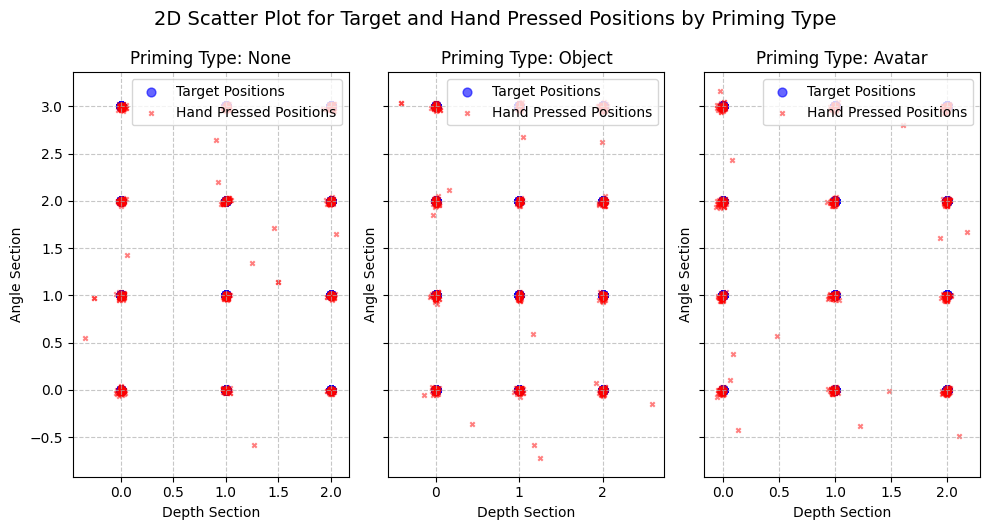

In [55]:
import matplotlib.pyplot as plt
import pandas as pd

# Assuming `final_translate_newdf` contains your processed data

# Ensure numeric conversion for plotting
final_translate_newdf['DepthSection'] = pd.to_numeric(final_translate_newdf['DepthSection'], errors='coerce')
final_translate_newdf['AngleSection'] = pd.to_numeric(final_translate_newdf['AngleSection'], errors='coerce')

# Replace NaN in 'Priming Type' column with 'None'
final_translate_newdf['Priming Type'] = final_translate_newdf['Priming Type'].fillna('None')

# Check for the unique priming types
unique_priming_types = final_translate_newdf['Priming Type'].unique()

# Set up subplots: Create a grid layout for multiple plots
num_priming_types = len(unique_priming_types)
fig, axes = plt.subplots(1, num_priming_types, figsize=(10, 5), sharey=True)

# If there's only one priming type, `axes` won't be a list, so wrap it
if num_priming_types == 1:
    axes = [axes]

# Loop through each Priming Type and create a scatter plot
for ax, priming_type in zip(axes, unique_priming_types):
    # Filter data for the current Priming Type
    priming_data = final_translate_newdf[final_translate_newdf['Priming Type'] == priming_type]
    
    # Scatter plot for target positions
    ax.scatter(
        priming_data['DepthSection'],
        priming_data['AngleSection'],
        c='blue',
        s=40,
        alpha=0.6,
        label="Target Positions"
    )
    
    # Scatter plot for hand-pressed positions
    ax.scatter(
        priming_data['DepthSection'] + priming_data['HandPressedX_Rel'],
        priming_data['AngleSection'] + priming_data['HandPressedZ_Rel'],
        c='red',
        s=10,
        alpha=0.5,
        marker='x',
        label="Hand Pressed Positions"
    )
    
    # Set subplot title and labels
    ax.set_title(f"Priming Type: {priming_type if priming_type != 'Unknown' else 'None'}")
    ax.set_xlabel("Depth Section")
    ax.set_ylabel("Angle Section")
    ax.legend(loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.7)

# Adjust layout for better spacing
plt.tight_layout()
plt.suptitle("2D Scatter Plot for Target and Hand Pressed Positions by Priming Type", fontsize=14, y=1.05)
plt.show()


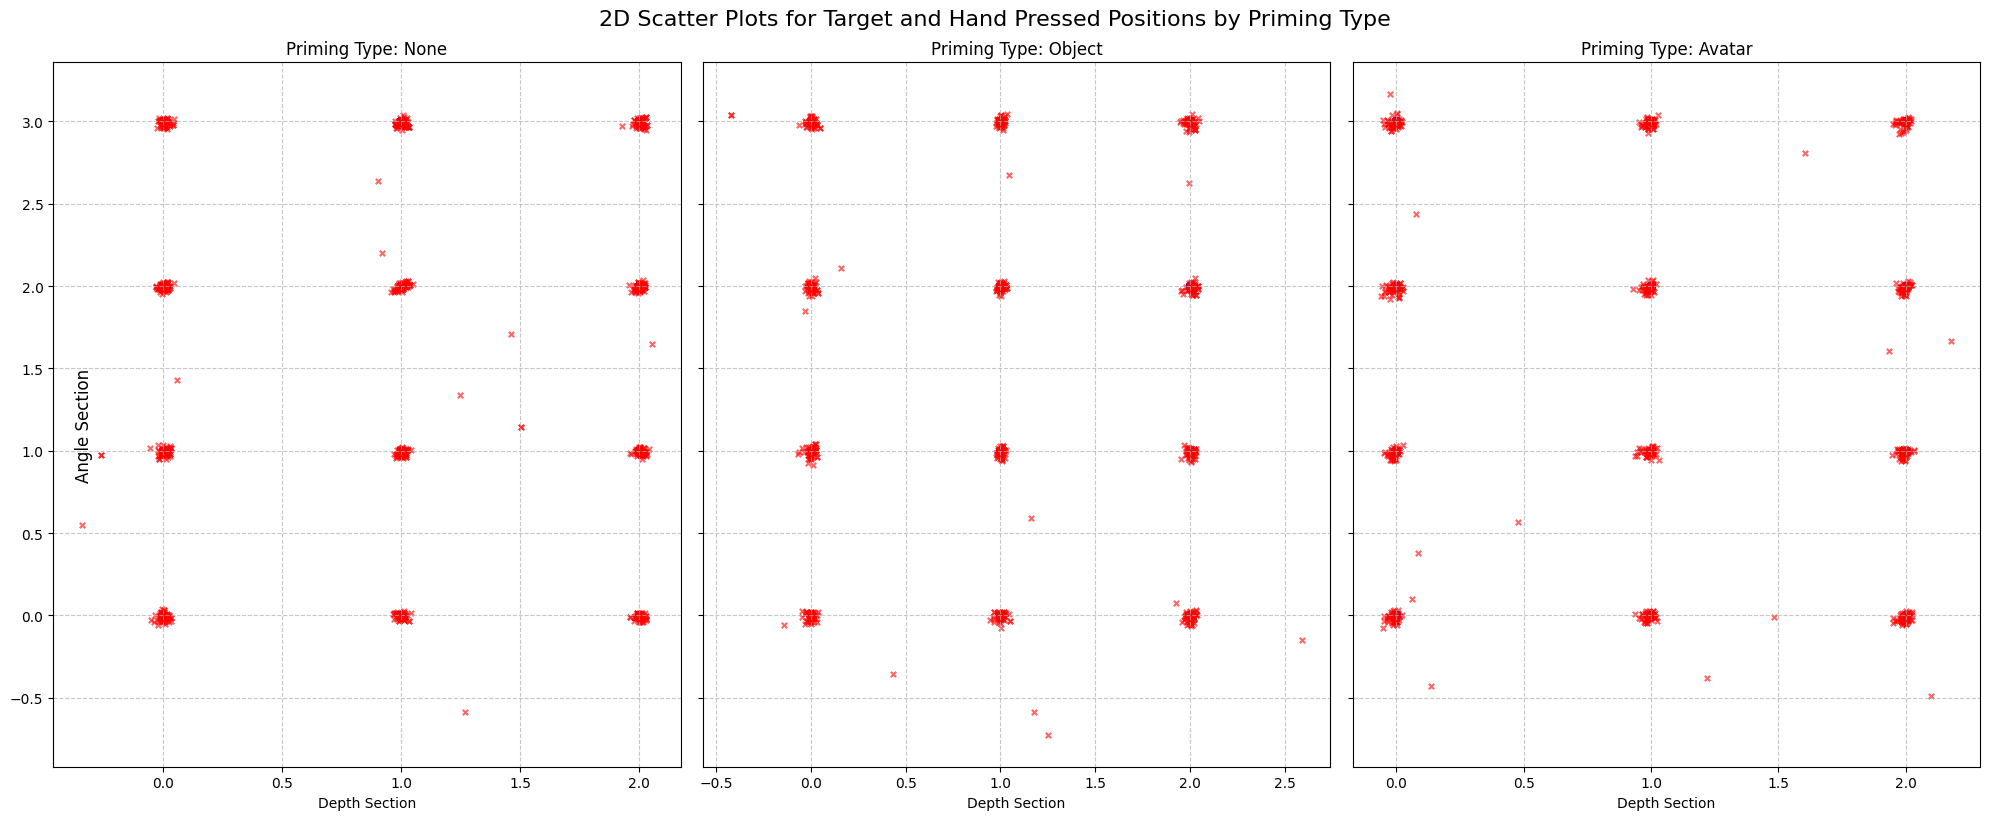

In [56]:
import matplotlib.pyplot as plt
import pandas as pd

# Assuming `final_translate_newdf` is already loaded
# Ensure all relevant columns are numeric
columns_to_numeric = ['DepthSection', 'AngleSection', 'HandPressedX_Rel', 'HandPressedZ_Rel']
for col in columns_to_numeric:
    final_translate_newdf[col] = pd.to_numeric(final_translate_newdf[col], errors='coerce')

# Fill any missing values in 'Priming Type' with 'None'
final_translate_newdf['Priming Type'] = final_translate_newdf['Priming Type'].fillna('None')

# Check for unique priming types
unique_priming_types = final_translate_newdf['Priming Type'].unique()

# Set up the subplots for each priming type
num_priming_types = len(unique_priming_types)
fig, axes = plt.subplots(1, num_priming_types, figsize=(20, 8), sharey=True)

# If there's only one priming type, ensure `axes` is a list
if num_priming_types == 1:
    axes = [axes]

# Loop through each Priming Type and create a scatter plot
for ax, priming_type in zip(axes, unique_priming_types):
    # Filter data for the current Priming Type
    priming_data = final_translate_newdf[final_translate_newdf['Priming Type'] == priming_type]
    
    if priming_data.empty:
        ax.set_title(f"Priming Type: {priming_type}")
        ax.text(0.5, 0.5, "No Data Available", fontsize=14, ha='center', va='center')
        ax.set_xlabel("Depth Section")
        ax.set_ylabel("Angle Section")
        continue

    # Scatter plot for target positions
    ax.scatter(
        priming_data['DepthSection'],
        priming_data['AngleSection'],
        c='blue',
        s=30,
        alpha=0.6,
        label="Target Positions"
    )

    # Scatter plot for hand-pressed positions
    ax.scatter(
        priming_data['DepthSection'] + priming_data['HandPressedX_Rel'],
        priming_data['AngleSection'] + priming_data['HandPressedZ_Rel'],
        c='red',
        s=15,
        alpha=0.6,
        marker='x',
        label="Hand Pressed Positions"
    )

    # Set titles and labels for each subplot
    ax.set_title(f"Priming Type: {priming_type}")
    ax.set_xlabel("Depth Section")
    ax.grid(True, linestyle='--', alpha=0.7)

# Set a shared y-label
fig.text(0.04, 0.5, "Angle Section", va='center', rotation='vertical', fontsize=12)

# Adjust layout
plt.tight_layout()
plt.suptitle("2D Scatter Plots for Target and Hand Pressed Positions by Priming Type", fontsize=16, y=1.02)

# Show the plot
plt.show()


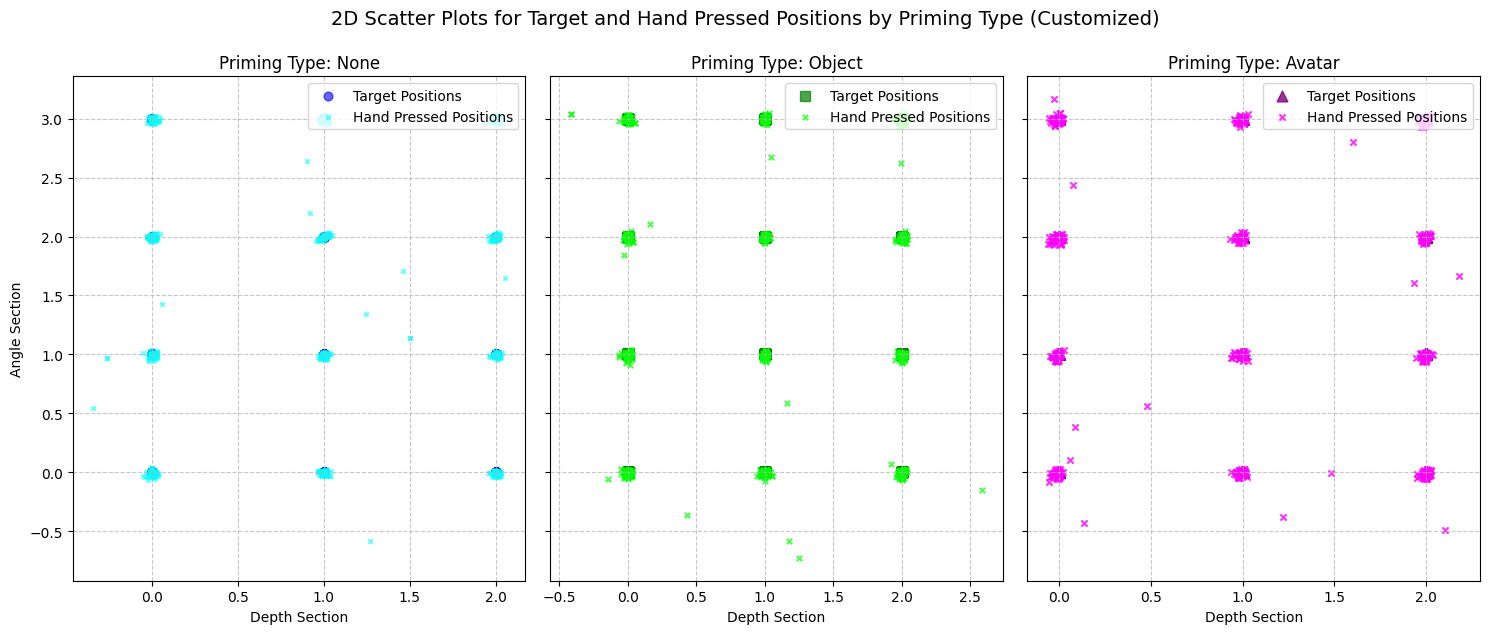

In [57]:
import matplotlib.pyplot as plt
import pandas as pd

# Ensure numeric conversion for plotting
final_translate_newdf['DepthSection'] = pd.to_numeric(final_translate_newdf['DepthSection'], errors='coerce')
final_translate_newdf['AngleSection'] = pd.to_numeric(final_translate_newdf['AngleSection'], errors='coerce')

# Replace NaN in 'Priming Type' column with 'None'
final_translate_newdf['Priming Type'] = final_translate_newdf['Priming Type'].fillna('None')

# Define customizations for each priming type
priming_customization = {
    'None': {'color_target': 'blue', 'color_hand': 'cyan', 'marker': 'o', 'size_target': 40, 'size_hand': 10, 'alpha': 0.6},
    'Object': {'color_target': 'green', 'color_hand': 'lime', 'marker': 's', 'size_target': 50, 'size_hand': 15, 'alpha': 0.7},
    'Avatar': {'color_target': 'purple', 'color_hand': 'magenta', 'marker': '^', 'size_target': 60, 'size_hand': 20, 'alpha': 0.8}
}

# Check for the unique priming types
unique_priming_types = final_translate_newdf['Priming Type'].unique()

# Set up subplots: Create a grid layout for multiple plots
num_priming_types = len(unique_priming_types)
fig, axes = plt.subplots(1, num_priming_types, figsize=(15, 6), sharey=True)

# If there's only one priming type, `axes` won't be a list, so wrap it
if num_priming_types == 1:
    axes = [axes]

# Loop through each Priming Type and create a scatter plot with custom styles
for ax, priming_type in zip(axes, unique_priming_types):
    # Filter data for the current Priming Type
    priming_data = final_translate_newdf[final_translate_newdf['Priming Type'] == priming_type]
    
    # Retrieve customization settings for the current priming type
    custom = priming_customization.get(priming_type, priming_customization['None'])
    
    # Scatter plot for target positions
    ax.scatter(
        priming_data['DepthSection'],
        priming_data['AngleSection'],
        c=custom['color_target'],
        s=custom['size_target'],
        alpha=custom['alpha'],
        marker=custom['marker'],
        label="Target Positions"
    )
    
    # Scatter plot for hand-pressed positions
    ax.scatter(
        priming_data['DepthSection'] + priming_data['HandPressedX_Rel'],
        priming_data['AngleSection'] + priming_data['HandPressedZ_Rel'],
        c=custom['color_hand'],
        s=custom['size_hand'],
        alpha=custom['alpha'],
        marker='x',
        label="Hand Pressed Positions"
    )
    
    # Set subplot title and labels
    ax.set_title(f"Priming Type: {priming_type}")
    ax.set_xlabel("Depth Section")
    if ax == axes[0]:
        ax.set_ylabel("Angle Section")
    ax.legend(loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.7)

# Adjust layout for better spacing
plt.tight_layout()
plt.suptitle("2D Scatter Plots for Target and Hand Pressed Positions by Priming Type (Customized)", fontsize=14, y=1.05)

# Show the final customized plot
plt.show()


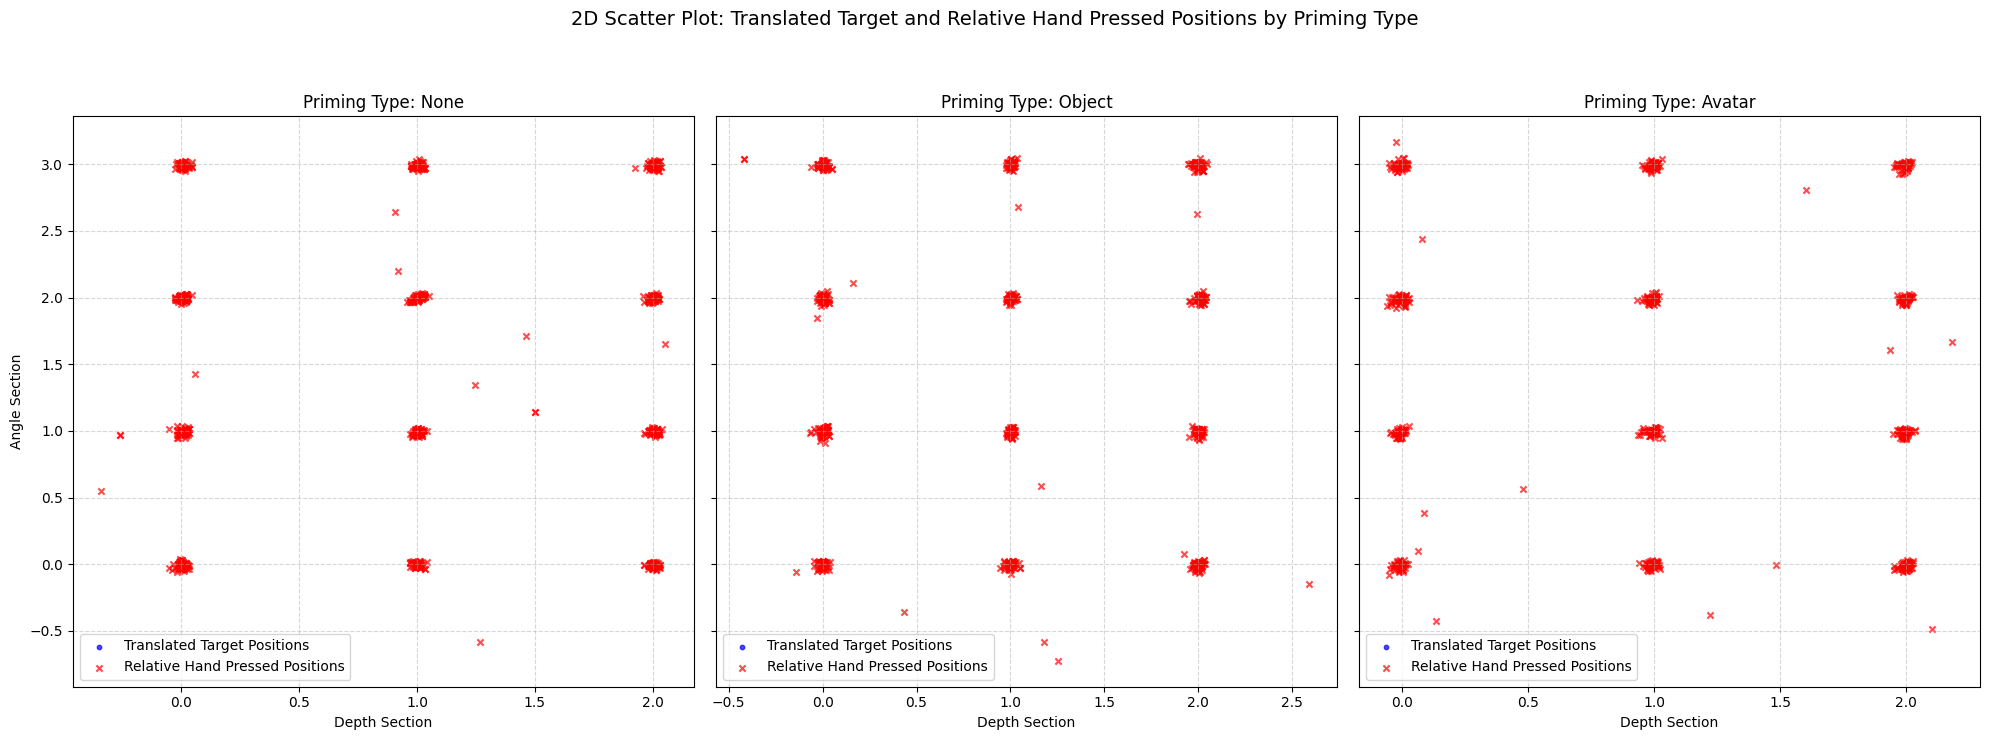

In [58]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Assuming 'final_translate_newdf' contains translated data
# Ensure numeric conversion for plotting
final_translate_newdf['DepthSection'] = pd.to_numeric(final_translate_newdf['DepthSection'], errors='coerce')
final_translate_newdf['AngleSection'] = pd.to_numeric(final_translate_newdf['AngleSection'], errors='coerce')
final_translate_newdf['HandPressedX_Rel'] = pd.to_numeric(final_translate_newdf['HandPressedX_Rel'], errors='coerce')
final_translate_newdf['HandPressedZ_Rel'] = pd.to_numeric(final_translate_newdf['HandPressedZ_Rel'], errors='coerce')

# Replace NaN in 'Priming Type' with 'None'
final_translate_newdf['Priming Type'] = final_translate_newdf['Priming Type'].fillna('None')

# Get unique priming types
unique_priming_types = final_translate_newdf['Priming Type'].unique()

# Set up the figure for subplots
fig, axes = plt.subplots(1, len(unique_priming_types), figsize=(20,7), sharey=True)

# Loop through each Priming Type
for idx, priming_type in enumerate(unique_priming_types):
    ax = axes[idx]
    
    # Filter data for the current priming type
    priming_data = final_translate_newdf[final_translate_newdf['Priming Type'] == priming_type]
    
    # Extract depth and angle section data
    depth_section = priming_data['DepthSection']
    angle_section = priming_data['AngleSection']
    
    # Calculate translated positions
    target_x_trans = priming_data['TargetPosX_Trans']
    target_z_trans = priming_data['TargetPosZ_Trans']
    hand_x_rel = target_x_trans + priming_data['HandPressedX_Rel']
    hand_z_rel = target_z_trans + priming_data['HandPressedZ_Rel']
    
    # Plot translated target positions as blue circles
    ax.scatter(
        depth_section, angle_section, 
        color='blue', s=10, alpha=0.7, label="Translated Target Positions"
    )
    
    # Plot relative hand-pressed positions as red 'x' markers
    ax.scatter(
        depth_section + hand_x_rel,
        angle_section + hand_z_rel,
        color='red', s=20, alpha=0.7, marker='x', label="Relative Hand Pressed Positions"
    )
    
    # Set titles and labels
    ax.set_title(f"Priming Type: {priming_type}")
    ax.set_xlabel("Depth Section")
    if idx == 0:  # Set Y-axis label only for the first subplot
        ax.set_ylabel("Angle Section")
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend()

# Add main title
plt.suptitle("2D Scatter Plot: Translated Target and Relative Hand Pressed Positions by Priming Type", fontsize=14, y=1.05)

# Optimize layout
plt.tight_layout()
plt.show()
